In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive"

for item in os.listdir(BASE_PATH):
    full_path = os.path.join(BASE_PATH, item)
    if os.path.isdir(full_path):
        print(f"📁 {item}")

📁 Colab Notebooks
📁 صورة
📁 Classroom
📁 Research
📁 Sprint2_Oral_Disease_Classification


In [ ]:
import os

DATA_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

for root, dirs, files in os.walk(DATA_PATH):
    level = root.replace(DATA_PATH, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}📁 {os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    📄 {file}")

    if len(files) > 5:
        print(f"{indent}    ... ({len(files)} files total)")

📁 Sprint2_Oral_Disease_Classification/
    📁 Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/
        📁 Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/
            📁 Data/
                📄 data.yaml
    📁 Calculus/
        📁 Calculus/
            📄 (1265).jpg
            📄 (1266).jpg
            📄 (1267).jpg
            📄 (1268).jpg
            📄 (1269).jpg
            ... (1296 files total)
    📁 Data caries/
        📁 Data caries/
            📁 caries augmented data set/
            📁 caries orignal data set/
    📁 hypodontia/
        📁 hypodontia/
            📄 (1224).jpg
            📄 (1225).jpg
            📄 (1226).JPG
            📄 (1227).JPG
            📄 (1228).jpg
            ... (1251 files total)
    📁 Tooth Discoloration/
        📁 Tooth Discoloration/
            📁 Tooth_discoloration_augmented_dataser/
            📁 tooth discoloration original dataset/
    📁 Mouth Ulcer/
        📁 Mouth Ulcer/
            📁 Mouth_Ulcer_augmented_Data

In [ ]:
import os
from collections import Counter

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for root, dirs, files in os.walk(BASE_PATH):
    image_files = [
        f for f in files
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    if image_files:
        relative_path = os.path.relpath(root, BASE_PATH)

        print(f"\n📁 {relative_path}")
        print(f"   Number of images: {len(image_files)}")


📁 Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data/images/val
   Number of images: 49

📁 Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data/images/train
   Number of images: 1040

📁 Calculus/Calculus
   Number of images: 1296

📁 Data caries/Data caries/caries augmented data set/preview
   Number of images: 2382

📁 Data caries/Data caries/caries orignal data set/done
   Number of images: 219

📁 hypodontia/hypodontia
   Number of images: 1251

📁 Tooth Discoloration/Tooth Discoloration/Tooth_discoloration_augmented_dataser/preview
   Number of images: 1834

📁 Tooth Discoloration/Tooth Discoloration/tooth discoloration original dataset/tooth discoloration original dataset
   Number of images: 183

📁 Mouth Ulcer/Mouth Ulcer/Mouth_Ulcer_augmented_DataSet/preview
   Number of images: 2541

📁 Mouth Ulcer/Mouth Ulcer/ulcer

In [ ]:
import os
from PIL import Image
from collections import defaultdict

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

# المجلدات المتوقع استخدامها في التصنيف
CLASS_DIRS = {
    "Calculus": os.path.join(BASE_PATH, "Calculus", "Calculus"),

    "Caries_Original": os.path.join(
        BASE_PATH, "Data caries", "Data caries",
        "caries orignal data set", "done"
    ),

    "Caries_Augmented": os.path.join(
        BASE_PATH, "Data caries", "Data caries",
        "caries augmented data set", "preview"
    ),

    "Gingivitis": os.path.join(
        BASE_PATH, "Gingivitis", "Gingivitis"
    ),

    "Hypodontia": os.path.join(
        BASE_PATH, "hypodontia", "hypodontia"
    ),

    "Mouth_Ulcer_Original": os.path.join(
        BASE_PATH, "Mouth Ulcer", "Mouth Ulcer",
        "ulcer original dataset", "ulcer original dataset"
    ),

    "Mouth_Ulcer_Augmented": os.path.join(
        BASE_PATH, "Mouth Ulcer", "Mouth Ulcer",
        "Mouth_Ulcer_augmented_DataSet", "preview"
    ),

    "Tooth_Discoloration_Original": os.path.join(
        BASE_PATH, "Tooth Discoloration", "Tooth Discoloration",
        "tooth discoloration original dataset",
        "tooth discoloration original dataset"
    ),

    "Tooth_Discoloration_Augmented": os.path.join(
        BASE_PATH, "Tooth Discoloration", "Tooth Discoloration",
        "Tooth_discoloration_augmented_dataser", "preview"
    )
}

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for name, folder in CLASS_DIRS.items():
    if not os.path.isdir(folder):
        print(f"\n❌ {name}: Folder not found")
        print(folder)
        continue

    image_paths = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    valid_images = 0
    invalid_images = 0
    image_sizes = defaultdict(int)

    for path in image_paths:
        try:
            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                image_sizes[img.size] += 1

            valid_images += 1

        except Exception:
            invalid_images += 1

    print(f"\n📁 {name}")
    print(f"Total images: {len(image_paths)}")
    print(f"Valid images: {valid_images}")
    print(f"Invalid images: {invalid_images}")
    print(f"Most common dimensions: {sorted(image_sizes.items(), key=lambda x: x[1], reverse=True)[:5]}")


📁 Calculus
Total images: 1296
Valid images: 1296
Invalid images: 0
Most common dimensions: [((612, 408), 549), ((612, 405), 81), ((612, 407), 81), ((612, 293), 45), ((612, 390), 36)]

📁 Caries_Original
Total images: 219
Valid images: 219
Invalid images: 0
Most common dimensions: [((612, 408), 58), ((275, 183), 14), ((408, 612), 9), ((259, 194), 5), ((305, 165), 4)]

📁 Caries_Augmented
Total images: 2382
Valid images: 2382
Invalid images: 0
Most common dimensions: [((612, 408), 572), ((275, 183), 127), ((408, 612), 85), ((259, 194), 45), ((612, 459), 37)]

📁 Gingivitis
Total images: 2349
Valid images: 2349
Invalid images: 0
Most common dimensions: [((612, 408), 1228), ((612, 406), 100), ((612, 407), 99), ((612, 405), 65), ((612, 317), 45)]

📁 Hypodontia
Total images: 1251
Valid images: 1251
Invalid images: 0
Most common dimensions: [((612, 408), 180), ((612, 407), 18), ((153, 55), 18), ((247, 204), 9), ((300, 168), 9)]

📁 Mouth_Ulcer_Original
Total images: 265
Valid images: 265
Invalid

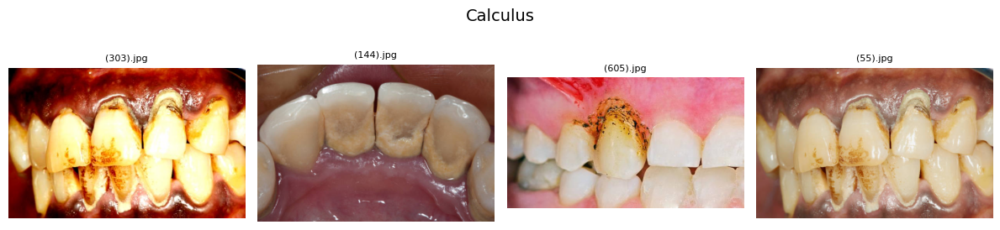

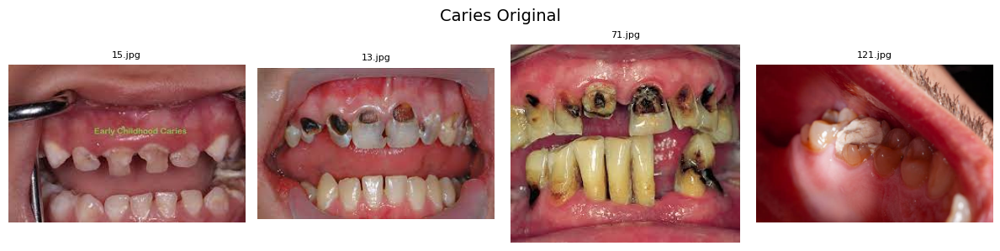

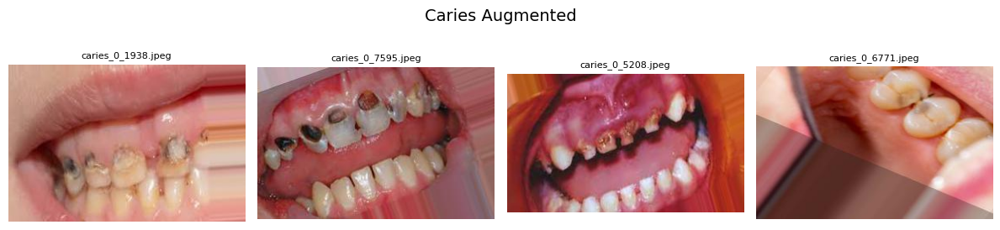

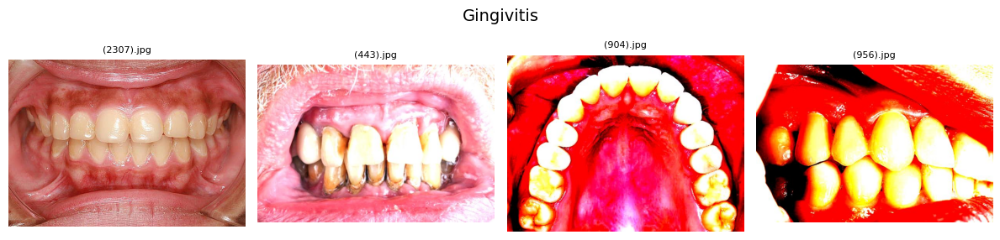

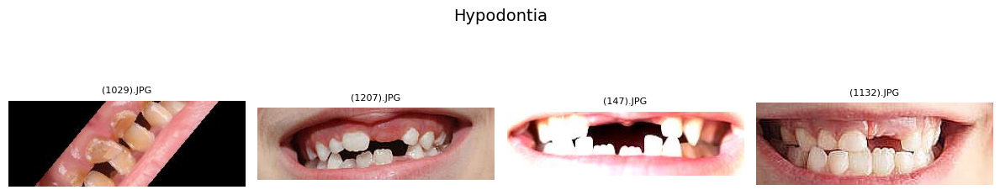

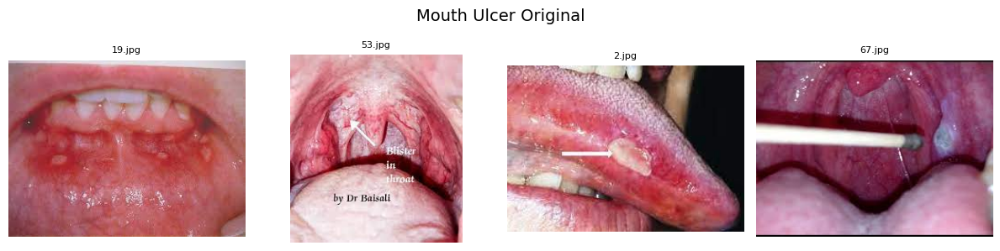

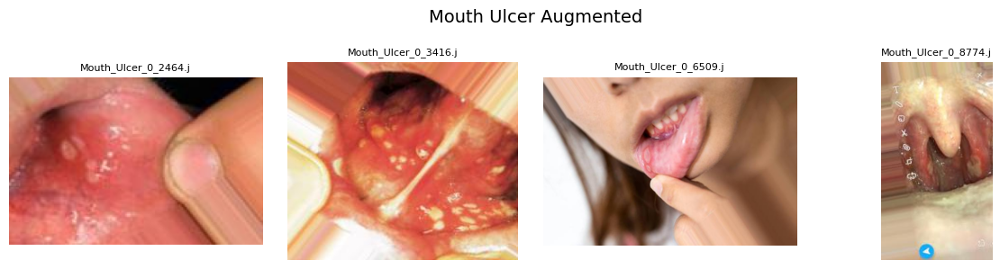

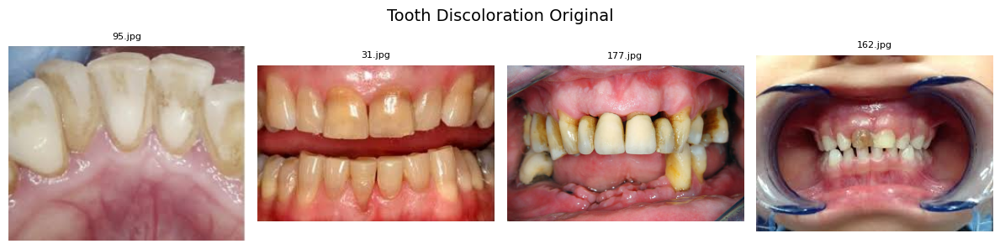

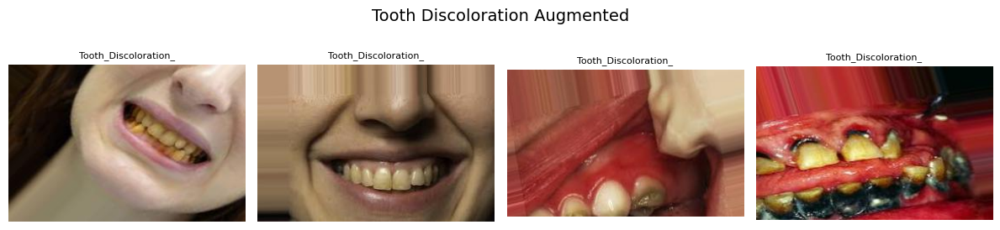

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

# عرض عينات من الفئات الأصلية والمجلدات التي نحتاج لفحصها
SAMPLE_DIRS = {
    "Calculus": CLASS_DIRS["Calculus"],
    "Caries Original": CLASS_DIRS["Caries_Original"],
    "Caries Augmented": CLASS_DIRS["Caries_Augmented"],
    "Gingivitis": CLASS_DIRS["Gingivitis"],
    "Hypodontia": CLASS_DIRS["Hypodontia"],
    "Mouth Ulcer Original": CLASS_DIRS["Mouth_Ulcer_Original"],
    "Mouth Ulcer Augmented": CLASS_DIRS["Mouth_Ulcer_Augmented"],
    "Tooth Discoloration Original": CLASS_DIRS["Tooth_Discoloration_Original"],
    "Tooth Discoloration Augmented": CLASS_DIRS["Tooth_Discoloration_Augmented"],
}

for class_name, folder in SAMPLE_DIRS.items():
    image_files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    samples = random.sample(image_files, min(4, len(image_files)))

    fig, axes = plt.subplots(1, len(samples), figsize=(12, 3))
    fig.suptitle(class_name, fontsize=14)

    if len(samples) == 1:
        axes = [axes]

    for ax, image_path in zip(axes, samples):
        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(os.path.basename(image_path)[:20], fontsize=8)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd

dataset_summary = pd.DataFrame([
    {
        "Class": "Calculus",
        "Original": 1296,
        "Pre_Augmented": 0
    },
    {
        "Class": "Caries",
        "Original": 219,
        "Pre_Augmented": 2382
    },
    {
        "Class": "Gingivitis",
        "Original": 2349,
        "Pre_Augmented": 0
    },
    {
        "Class": "Hypodontia",
        "Original": 1251,
        "Pre_Augmented": 0
    },
    {
        "Class": "Mouth Ulcer",
        "Original": 265,
        "Pre_Augmented": 2541
    },
    {
        "Class": "Tooth Discoloration",
        "Original": 183,
        "Pre_Augmented": 1834
    }
])

dataset_summary["Total"] = (
    dataset_summary["Original"]
    + dataset_summary["Pre_Augmented"]
)

print(dataset_summary.to_string(index=False))

print("\nTotal original images:",
      dataset_summary["Original"].sum())

print("Total pre-augmented images:",
      dataset_summary["Pre_Augmented"].sum())

print("Total images:",
      dataset_summary["Total"].sum())

              Class  Original  Pre_Augmented  Total
           Calculus      1296              0   1296
             Caries       219           2382   2601
         Gingivitis      2349              0   2349
         Hypodontia      1251              0   1251
        Mouth Ulcer       265           2541   2806
Tooth Discoloration       183           1834   2017

Total original images: 5563
Total pre-augmented images: 6757
Total images: 12320


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

WORK_PATH = os.path.join(PROJECT_PATH, "prepared_dataset")

SPLITS = ["train", "validation", "test"]

CLASSES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth_Ulcer",
    "Tooth_Discoloration"
]

for split in SPLITS:
    for class_name in CLASSES:
        folder = os.path.join(WORK_PATH, split, class_name)
        os.makedirs(folder, exist_ok=True)

print("Prepared dataset folders created successfully.")
print("Location:", WORK_PATH)

for split in SPLITS:
    print(f"{split}:")
    for class_name in CLASSES:
        print("  -", class_name)

Prepared dataset folders created successfully.
Location: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/prepared_dataset
train:
  - Calculus
  - Caries
  - Gingivitis
  - Hypodontia
  - Mouth_Ulcer
  - Tooth_Discoloration
validation:
  - Calculus
  - Caries
  - Gingivitis
  - Hypodontia
  - Mouth_Ulcer
  - Tooth_Discoloration
test:
  - Calculus
  - Caries
  - Gingivitis
  - Hypodontia
  - Mouth_Ulcer
  - Tooth_Discoloration


In [ ]:
import os
import hashlib
from collections import defaultdict

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

SOURCE_DIRS = {
    "Calculus": os.path.join(BASE_PATH, "Calculus", "Calculus"),

    "Caries_Original": os.path.join(
        BASE_PATH, "Data caries", "Data caries",
        "caries orignal data set", "done"
    ),
    "Caries_Augmented": os.path.join(
        BASE_PATH, "Data caries", "Data caries",
        "caries augmented data set", "preview"
    ),

    "Gingivitis": os.path.join(BASE_PATH, "Gingivitis", "Gingivitis"),

    "Hypodontia": os.path.join(BASE_PATH, "hypodontia", "hypodontia"),

    "Mouth_Ulcer_Original": os.path.join(
        BASE_PATH, "Mouth Ulcer", "Mouth Ulcer",
        "ulcer original dataset", "ulcer original dataset"
    ),
    "Mouth_Ulcer_Augmented": os.path.join(
        BASE_PATH, "Mouth Ulcer", "Mouth Ulcer",
        "Mouth_Ulcer_augmented_DataSet", "preview"
    ),

    "Tooth_Discoloration_Original": os.path.join(
        BASE_PATH, "Tooth Discoloration", "Tooth Discoloration",
        "tooth discoloration original dataset",
        "tooth discoloration original dataset"
    ),
    "Tooth_Discoloration_Augmented": os.path.join(
        BASE_PATH, "Tooth Discoloration", "Tooth Discoloration",
        "Tooth_discoloration_augmented_dataser", "preview"
    )
}

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

hash_groups = defaultdict(list)
image_count = 0

for source_name, folder in SOURCE_DIRS.items():
    if not os.path.isdir(folder):
        print(f"WARNING: Folder not found: {folder}")
        continue

    for filename in os.listdir(folder):
        if not filename.lower().endswith(IMAGE_EXTENSIONS):
            continue

        path = os.path.join(folder, filename)

        try:
            digest = hashlib.sha256()

            with open(path, "rb") as file:
                for chunk in iter(lambda: file.read(1024 * 1024), b""):
                    digest.update(chunk)

            hash_groups[digest.hexdigest()].append(
                (source_name, filename, path)
            )
            image_count += 1

        except OSError as error:
            print(f"Could not read {path}: {error}")

duplicate_groups = {
    digest: files
    for digest, files in hash_groups.items()
    if len(files) > 1
}

duplicate_images = sum(
    len(files) - 1
    for files in duplicate_groups.values()
)

print("Total images scanned:", image_count)
print("Unique image contents:", len(hash_groups))
print("Exact duplicate groups:", len(duplicate_groups))
print("Extra duplicate copies:", duplicate_images)

print("\nExamples of duplicate groups:")
for files in list(duplicate_groups.values())[:15]:
    print("\nGroup:")
    for source_name, filename, path in files:
        print(f"  {source_name} | {filename}")

Total images scanned: 12320
Unique image contents: 10656
Exact duplicate groups: 775
Extra duplicate copies: 1664

Examples of duplicate groups:

Group:
  Calculus | (1267).jpg
  Gingivitis | (2222).jpg
  Gingivitis | (2228).jpg
  Gingivitis | (2304).jpg
  Gingivitis | (2095).jpg
  Gingivitis | (2143).jpg

Group:
  Calculus | (1268).jpg
  Calculus | (1285).jpg
  Calculus | (1159).jpg
  Calculus | (1212).jpg
  Calculus | (1241).jpg
  Gingivitis | (2257).jpg
  Gingivitis | (2316).jpg
  Gingivitis | (2160).jpg

Group:
  Calculus | (1269).jpg
  Calculus | (1155).jpg
  Calculus | (1214).jpg
  Calculus | (1242).jpg
  Calculus | (1258).jpg
  Gingivitis | (2224).jpg
  Gingivitis | (2308).jpg
  Gingivitis | (2140).jpg
  Gingivitis | (2146).jpg
  Hypodontia | (1246).jpg

Group:
  Calculus | (127).jpg
  Gingivitis | (204).jpg

Group:
  Calculus | (1270).jpg
  Calculus | (1289).jpg
  Calculus | (1210).jpg
  Calculus | (1211).jpg
  Calculus | (1244).jpg
  Gingivitis | (2232).jpg
  Gingivitis | (231

In [ ]:
from collections import Counter, defaultdict
import pandas as pd

cross_class_groups = []
same_class_groups = []

for digest, files in duplicate_groups.items():

    classes = sorted(set(source_name for source_name, _, _ in files))

    group_info = {
        "SHA256": digest,
        "Number_of_Copies": len(files),
        "Number_of_Classes": len(classes),
        "Classes": ", ".join(classes),
        "Files": files
    }

    if len(classes) > 1:
        cross_class_groups.append(group_info)
    else:
        same_class_groups.append(group_info)

print("===== DUPLICATE ANALYSIS =====")
print("Total duplicate groups:", len(duplicate_groups))
print("Groups within the same class:", len(same_class_groups))
print("Groups across different classes:", len(cross_class_groups))

print("\n===== CROSS-CLASS DUPLICATES BY CLASS COMBINATION =====")

combination_counts = Counter(
    group["Classes"]
    for group in cross_class_groups
)

for combination, count in combination_counts.most_common():
    print(f"{combination}: {count} groups")

print("\n===== EXAMPLES OF CROSS-CLASS DUPLICATES =====")

for group in cross_class_groups[:20]:
    print(f"\nClasses: {group['Classes']}")
    print(f"Copies: {group['Number_of_Copies']}")

    for source_name, filename, _ in group["Files"]:
        print(f"  {source_name}: {filename}")

===== DUPLICATE ANALYSIS =====
Total duplicate groups: 775
Groups within the same class: 383
Groups across different classes: 392

===== CROSS-CLASS DUPLICATES BY CLASS COMBINATION =====
Calculus, Gingivitis: 353 groups
Calculus, Hypodontia: 9 groups
Gingivitis, Hypodontia: 9 groups
Calculus, Gingivitis, Hypodontia: 8 groups
Calculus, Caries_Original, Gingivitis: 4 groups
Calculus, Caries_Original: 3 groups
Caries_Original, Gingivitis: 3 groups
Calculus, Gingivitis, Tooth_Discoloration_Original: 2 groups
Calculus, Gingivitis, Hypodontia, Tooth_Discoloration_Original: 1 groups

===== EXAMPLES OF CROSS-CLASS DUPLICATES =====

Classes: Calculus, Gingivitis
Copies: 6
  Calculus: (1267).jpg
  Gingivitis: (2222).jpg
  Gingivitis: (2228).jpg
  Gingivitis: (2304).jpg
  Gingivitis: (2095).jpg
  Gingivitis: (2143).jpg

Classes: Calculus, Gingivitis
Copies: 8
  Calculus: (1268).jpg
  Calculus: (1285).jpg
  Calculus: (1159).jpg
  Calculus: (1212).jpg
  Calculus: (1241).jpg
  Gingivitis: (2257).jpg

Calculus/Gingivitis duplicate groups: 368


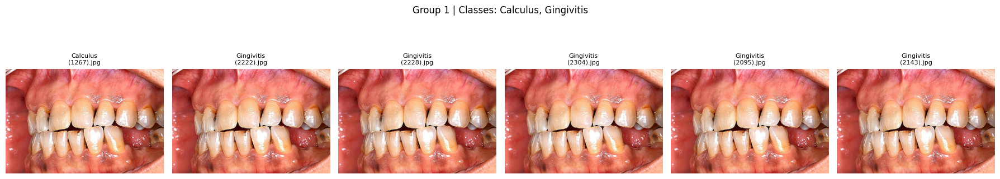

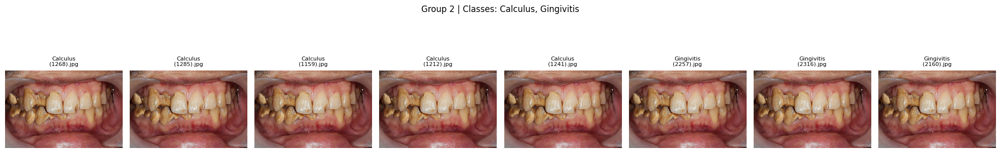

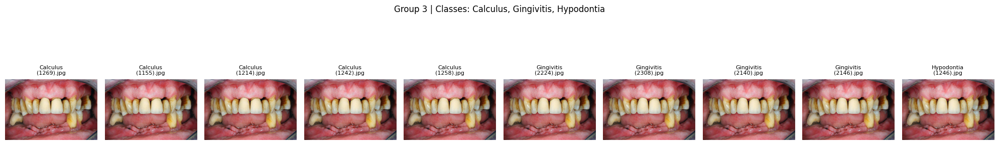

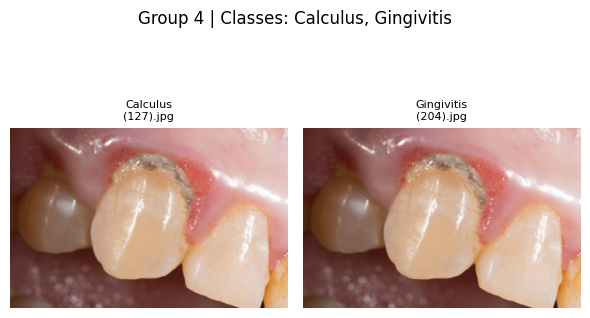

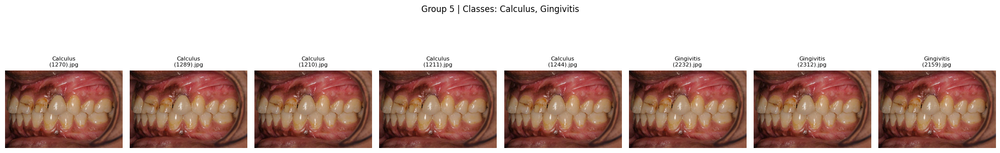

...

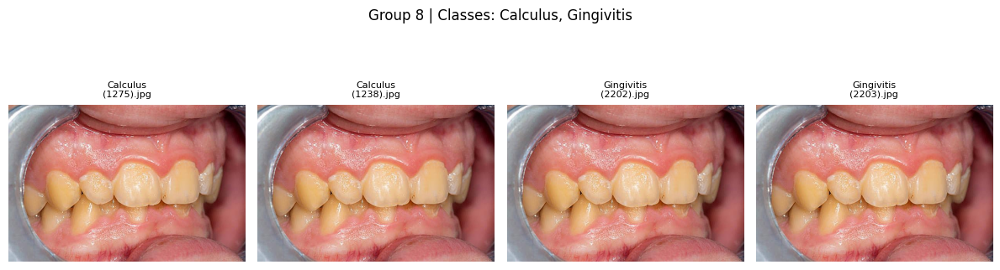

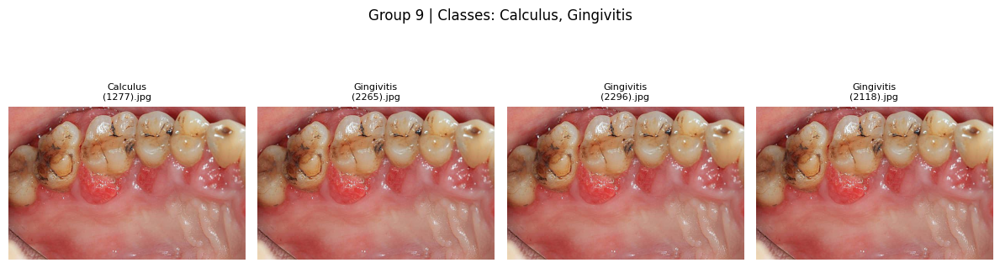

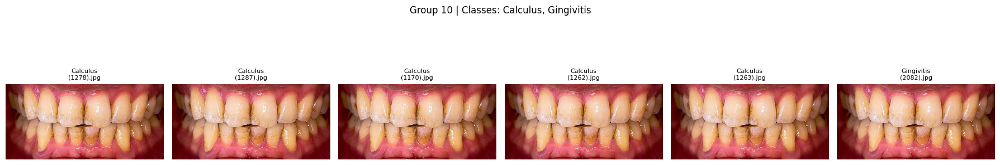

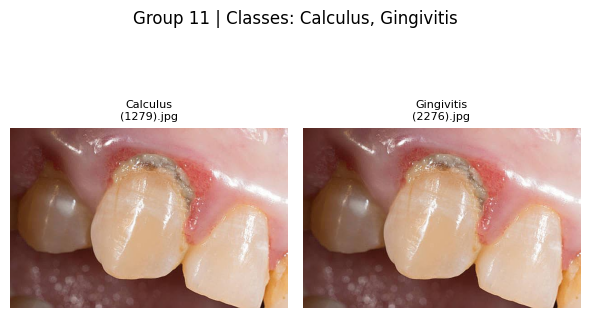

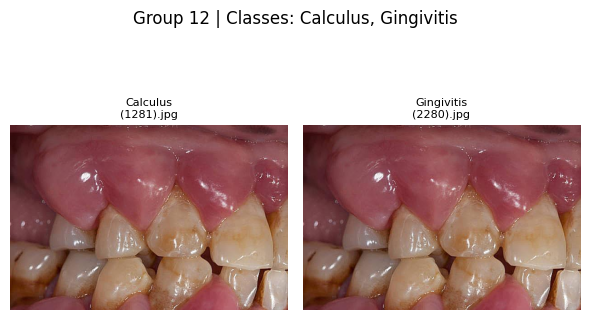

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# اختيار مجموعات الصور المتطابقة بين Calculus وGingivitis
target_groups = [
    group for group in cross_class_groups
    if "Calculus" in group["Classes"]
    and "Gingivitis" in group["Classes"]
]

print("Calculus/Gingivitis duplicate groups:", len(target_groups))

for group_number, group in enumerate(target_groups[:12], start=1):

    files = group["Files"]

    fig, axes = plt.subplots(
        1, len(files),
        figsize=(min(20, 3 * len(files)), 4)
    )

    if len(files) == 1:
        axes = [axes]

    fig.suptitle(
        f"Group {group_number} | Classes: {group['Classes']}",
        fontsize=12
    )

    for ax, (source_name, filename, path) in zip(axes, files):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{source_name}\n{filename}",
            fontsize=8
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd

conflicting_records = []

for group in cross_class_groups:
    for source_name, filename, path in group["Files"]:
        conflicting_records.append({
            "SHA256": group["SHA256"],
            "Source_Class": source_name,
            "Filename": filename,
            "Path": path,
            "Conflicting_Classes": group["Classes"],
            "Number_of_Copies": group["Number_of_Copies"]
        })

conflicts_df = pd.DataFrame(conflicting_records)

print("Conflicting image records:", len(conflicts_df))
print("\nRecords by source class:")
print(conflicts_df["Source_Class"].value_counts())

print("\nConflicting groups by class combination:")
print(
    conflicts_df[["SHA256", "Conflicting_Classes"]]
    .drop_duplicates()["Conflicting_Classes"]
    .value_counts()
)

# حفظ تقرير المراجعة فقط، دون تعديل الصور
REPORT_PATH = (
    "/content/drive/MyDrive/"
    "Sprint2_Oral_Disease_Classification/"
    "conflicting_images_report.csv"
)

conflicts_df.to_csv(REPORT_PATH, index=False)

print("\nReport saved to:", REPORT_PATH)

Conflicting image records: 1510

Records by source class:
Source_Class
Gingivitis                      734
Calculus                        731
Hypodontia                       27
Caries_Original                  14
Tooth_Discoloration_Original      4
Name: count, dtype: int64

Conflicting groups by class combination:
Conflicting_Classes
Calculus, Gingivitis                                              353
Calculus, Hypodontia                                                9
Gingivitis, Hypodontia                                              9
Calculus, Gingivitis, Hypodontia                                    8
Calculus, Caries_Original, Gingivitis                               4
Caries_Original, Gingivitis                                         3
Calculus, Caries_Original                                           3
Calculus, Gingivitis, Tooth_Discoloration_Original                  2
Calculus, Gingivitis, Hypodontia, Tooth_Discoloration_Original      1
Name: count, dtype: int64

Repo

In [ ]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

# ربط كل مجلد بالفئة الطبية الحقيقية
SOURCE_TO_CLASS = {
    "Calculus": "Calculus",
    "Caries_Original": "Caries",
    "Caries_Augmented": "Caries",
    "Gingivitis": "Gingivitis",
    "Hypodontia": "Hypodontia",
    "Mouth_Ulcer_Original": "Mouth_Ulcer",
    "Mouth_Ulcer_Augmented": "Mouth_Ulcer",
    "Tooth_Discoloration_Original": "Tooth_Discoloration",
    "Tooth_Discoloration_Augmented": "Tooth_Discoloration",
}

# إعطاء الأولوية للصور الأصلية عند تكرار الصورة داخل الفئة
SOURCE_PRIORITY = {
    "Calculus": 0,
    "Caries_Original": 0,
    "Caries_Augmented": 1,
    "Gingivitis": 0,
    "Hypodontia": 0,
    "Mouth_Ulcer_Original": 0,
    "Mouth_Ulcer_Augmented": 1,
    "Tooth_Discoloration_Original": 0,
    "Tooth_Discoloration_Augmented": 1,
}

clean_records = []
excluded_records = []

for digest, files in hash_groups.items():

    # الفئات الطبية الفعلية التي ظهرت فيها الصورة
    actual_classes = {
        SOURCE_TO_CLASS[source_name]
        for source_name, filename, path in files
    }

    # الصورة متطابقة، لكنها تحمل تسميات طبية مختلفة
    if len(actual_classes) > 1:
        for source_name, filename, path in files:
            excluded_records.append({
                "SHA256": digest,
                "Class": SOURCE_TO_CLASS[source_name],
                "Source_Folder": source_name,
                "Filename": filename,
                "Path": path,
                "Reason": "Exact duplicate across different classes",
            })
        continue

    # الصورة تنتمي إلى فئة واحدة؛ نحتفظ بنسخة واحدة فقط
    sorted_files = sorted(
        files,
        key=lambda item: (
            SOURCE_PRIORITY[item[0]],
            item[2].lower()
        )
    )

    source_name, filename, path = sorted_files[0]

    clean_records.append({
        "SHA256": digest,
        "Class": SOURCE_TO_CLASS[source_name],
        "Source_Folder": source_name,
        "Filename": filename,
        "Path": path,
        "Copies_Found": len(files),
    })

    # تسجيل النسخ الزائدة داخل الفئة نفسها
    for duplicate_source, duplicate_filename, duplicate_path in sorted_files[1:]:
        excluded_records.append({
            "SHA256": digest,
            "Class": SOURCE_TO_CLASS[duplicate_source],
            "Source_Folder": duplicate_source,
            "Filename": duplicate_filename,
            "Path": duplicate_path,
            "Reason": "Exact duplicate within the same class",
        })

clean_df = pd.DataFrame(clean_records)
excluded_df = pd.DataFrame(excluded_records)

# حفظ التقارير دون تعديل الصور الأصلية
clean_path = os.path.join(BASE_PATH, "clean_image_manifest.csv")
excluded_path = os.path.join(BASE_PATH, "excluded_image_manifest.csv")

clean_df.to_csv(clean_path, index=False)
excluded_df.to_csv(excluded_path, index=False)

print("===== CLEAN DATA MANIFEST =====")
print("Unique images retained:", len(clean_df))
print("\nImages retained per class:")
print(clean_df["Class"].value_counts().sort_index())

print("\n===== EXCLUDED IMAGES =====")
print("Image records excluded:", len(excluded_df))
print("\nExclusion reasons:")
print(excluded_df["Reason"].value_counts())

print("\n===== FILES SAVED =====")
print(clean_path)
print(excluded_path)

===== CLEAN DATA MANIFEST =====
Unique images retained: 10264

Images retained per class:
Class
Calculus                449
Caries                 2573
Gingivitis             1236
Hypodontia             1215
Mouth_Ulcer            2784
Tooth_Discoloration    2007
Name: count, dtype: int64

===== EXCLUDED IMAGES =====
Image records excluded: 2056

Exclusion reasons:
Reason
Exact duplicate across different classes    1510
Exact duplicate within the same class        546
Name: count, dtype: int64

===== FILES SAVED =====
/content/drive/MyDrive/Sprint2_Oral_Disease_Classification/clean_image_manifest.csv
/content/drive/MyDrive/Sprint2_Oral_Disease_Classification/excluded_image_manifest.csv


In [ ]:
import pandas as pd

original_counts = {
    "Calculus": 1296,
    "Caries": 2601,
    "Gingivitis": 2349,
    "Hypodontia": 1251,
    "Mouth_Ulcer": 2806,
    "Tooth_Discoloration": 2017
}

retained_counts = (
    clean_df["Class"]
    .value_counts()
    .to_dict()
)

comparison = pd.DataFrame({
    "Class": list(original_counts.keys()),
    "Images_Before": [
        original_counts[c] for c in original_counts
    ],
    "Images_After": [
        retained_counts.get(c, 0) for c in original_counts
    ]
})

comparison["Excluded"] = (
    comparison["Images_Before"]
    - comparison["Images_After"]
)

comparison["Retention_Percent"] = (
    comparison["Images_After"]
    / comparison["Images_Before"]
    * 100
).round(2)

print(comparison.to_string(index=False))

print("\nTotal before:", comparison["Images_Before"].sum())
print("Total after:", comparison["Images_After"].sum())

              Class  Images_Before  Images_After  Excluded  Retention_Percent
           Calculus           1296           449       847              34.65
             Caries           2601          2573        28              98.92
         Gingivitis           2349          1236      1113              52.62
         Hypodontia           1251          1215        36              97.12
        Mouth_Ulcer           2806          2784        22              99.22
Tooth_Discoloration           2017          2007        10              99.50

Total before: 12320
Total after: 10264


Number of matching groups: 368


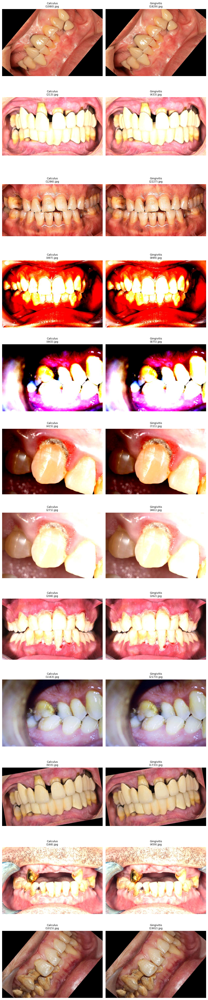

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# مجموعات الصور المتطابقة بين Calculus وGingivitis
target_groups = []

for digest, files in hash_groups.items():
    source_folders = {item[0] for item in files}

    if "Calculus" in source_folders and "Gingivitis" in source_folders:
        target_groups.append((digest, files))

print("Number of matching groups:", len(target_groups))

# عرض 12 مجموعة عشوائية للمراجعة البصرية
import random

random.seed(42)
sample_groups = random.sample(
    target_groups,
    min(12, len(target_groups))
)

fig, axes = plt.subplots(
    len(sample_groups), 2,
    figsize=(10, 4 * len(sample_groups))
)

if len(sample_groups) == 1:
    axes = [axes]

for i, (digest, files) in enumerate(sample_groups):
    calculus_file = next(
        item for item in files if item[0] == "Calculus"
    )
    gingivitis_file = next(
        item for item in files if item[0] == "Gingivitis"
    )

    for j, item in enumerate([calculus_file, gingivitis_file]):
        with Image.open(item[2]) as img:
            axes[i][j].imshow(img.convert("RGB"))

        axes[i][j].set_title(
            f"{item[0]}\n{item[1]}",
            fontsize=9
        )
        axes[i][j].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
!pip -q install ImageHash

In [ ]:
import os
import imagehash
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

clean_df = pd.read_csv(
    os.path.join(BASE_PATH, "clean_image_manifest.csv")
)

perceptual_hashes = []
failed_images = []

for _, row in tqdm(clean_df.iterrows(), total=len(clean_df)):
    try:
        with Image.open(row["Path"]) as img:
            phash = imagehash.phash(img.convert("RGB"))
        perceptual_hashes.append(str(phash))
    except Exception as e:
        failed_images.append({
            "Path": row["Path"],
            "Error": str(e)
        })
        perceptual_hashes.append(None)

clean_df["pHash"] = perceptual_hashes

hash_path = os.path.join(
    BASE_PATH, "image_hash_manifest.csv"
)

clean_df.to_csv(hash_path, index=False)

print("Images processed:", len(clean_df))
print("Failed images:", len(failed_images))
print("Hash manifest saved:", hash_path)

  0%|          | 0/10264 [00:00<?, ?it/s]

Images processed: 10264
Failed images: 0
Hash manifest saved: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/image_hash_manifest.csv


In [ ]:
import os
import imagehash
import pandas as pd
from collections import defaultdict
from tqdm.auto import tqdm

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

df = pd.read_csv(
    os.path.join(BASE_PATH, "image_hash_manifest.csv")
)

# Convert stored hashes to ImageHash objects
hashes = [
    imagehash.hex_to_hash(value)
    for value in df["pHash"]
]

# Group images with very similar perceptual hashes.
# Hamming distance <= 4 is a conservative initial threshold.
parent = list(range(len(df)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    root_a = find(a)
    root_b = find(b)
    if root_a != root_b:
        parent[root_b] = root_a

# Compare within each class first, to avoid joining different classes
# automatically based on visual similarity alone.
for class_name, indices in df.groupby("Class").groups.items():
    indices = list(indices)
    for pos, i in enumerate(tqdm(indices, desc=class_name)):
        for j in indices[pos + 1:]:
            if hashes[i] - hashes[j] <= 4:
                union(i, j)

groups = defaultdict(list)

for i in range(len(df)):
    groups[find(i)].append(i)

similar_groups = [
    members for members in groups.values()
    if len(members) > 1
]

print("Total images:", len(df))
print("Similar-image groups within classes:", len(similar_groups))
print("Images belonging to these groups:",
      sum(len(g) for g in similar_groups))
print("Largest group size:",
      max((len(g) for g in similar_groups), default=0))

Calculus:   0%|          | 0/449 [00:00<?, ?it/s]

Caries:   0%|          | 0/2573 [00:00<?, ?it/s]

Gingivitis:   0%|          | 0/1236 [00:00<?, ?it/s]

Hypodontia:   0%|          | 0/1215 [00:00<?, ?it/s]

Mouth_Ulcer:   0%|          | 0/2784 [00:00<?, ?it/s]

Tooth_Discoloration:   0%|          | 0/2007 [00:00<?, ?it/s]

Total images: 10264
Similar-image groups within classes: 392
Images belonging to these groups: 1377
Largest group size: 8


In [ ]:
import os
import pandas as pd
from collections import defaultdict

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

df = pd.read_csv(
    os.path.join(BASE_PATH, "image_hash_manifest.csv")
)

# Recreate perceptual hashes
import imagehash

hashes = [
    imagehash.hex_to_hash(value)
    for value in df["pHash"]
]

parent = list(range(len(df)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

# Rebuild groups within each class
for class_name, indices in df.groupby("Class").groups.items():
    indices = list(indices)

    for pos, i in enumerate(indices):
        for j in indices[pos + 1:]:
            if hashes[i] - hashes[j] <= 4:
                union(i, j)

groups = defaultdict(list)

for i in range(len(df)):
    groups[find(i)].append(i)

# Save a group ID for every image
group_ids = {}

for group_number, members in enumerate(groups.values(), start=1):
    for idx in members:
        group_ids[idx] = group_number

df["Similarity_Group"] = [
    group_ids[i] for i in range(len(df))
]

output_path = os.path.join(
    BASE_PATH, "image_similarity_groups.csv"
)

df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Total images:", len(df))
print("Total similarity groups:", df["Similarity_Group"].nunique())
print("Images in groups containing multiple images:",
      (df.groupby("Similarity_Group")["Similarity_Group"]
       .transform("size") > 1).sum())

Saved: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/image_similarity_groups.csv
Total images: 10264
Total similarity groups: 9279
Images in groups containing multiple images: 1377


In [ ]:
import os
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

df = pd.read_csv(
    os.path.join(BASE_PATH, "image_similarity_groups.csv")
)

# First split: 70% training, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(df, groups=df["Similarity_Group"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# Second split: half of temporary for validation, half for test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["Similarity_Group"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Save the split manifests
train_df["Split"] = "train"
val_df["Split"] = "validation"
test_df["Split"] = "test"

split_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

output_path = os.path.join(BASE_PATH, "dataset_split_manifest.csv")
split_df.to_csv(output_path, index=False)

# Report split sizes
print("Train:", len(train_df), f"({len(train_df)/len(df)*100:.2f}%)")
print("Validation:", len(val_df), f"({len(val_df)/len(df)*100:.2f}%)")
print("Test:", len(test_df), f"({len(test_df)/len(df)*100:.2f}%)")

print("\nClass distribution by split:")
print(pd.crosstab(split_df["Class"], split_df["Split"]))

print("\nManifest saved:", output_path)

Train: 7165 (69.81%)
Validation: 1578 (15.37%)
Test: 1521 (14.82%)

Class distribution by split:
Split                test  train  validation
Class                                       
Calculus               63    302          84
Caries                391   1804         378
Gingivitis            201    825         210
Hypodontia            160    853         202
Mouth_Ulcer           432   1936         416
Tooth_Discoloration   274   1445         288

Manifest saved: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/dataset_split_manifest.csv


In [ ]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

df = pd.read_csv(
    os.path.join(BASE_PATH, "dataset_split_manifest.csv")
)

group_overlap = {}

splits = {
    name: set(df.loc[df["Split"] == name, "Similarity_Group"])
    for name in ["train", "validation", "test"]
}

group_overlap["train_validation"] = (
    splits["train"] & splits["validation"]
)
group_overlap["train_test"] = (
    splits["train"] & splits["test"]
)
group_overlap["validation_test"] = (
    splits["validation"] & splits["test"]
)

print("===== GROUP LEAKAGE CHECK =====")

for pair, groups in group_overlap.items():
    print(f"{pair}: {len(groups)} overlapping groups")

if all(len(groups) == 0 for groups in group_overlap.values()):
    print("\nPASS: No similarity groups are shared between splits.")
else:
    print("\nWARNING: Group overlap detected.")

print("\n===== CLASS COUNTS =====")
print(pd.crosstab(df["Class"], df["Split"]))

print("\n===== SPLIT COUNTS =====")
print(df["Split"].value_counts())

===== GROUP LEAKAGE CHECK =====
train_validation: 0 overlapping groups
train_test: 0 overlapping groups
validation_test: 0 overlapping groups

PASS: No similarity groups are shared between splits.

===== CLASS COUNTS =====
Split                test  train  validation
Class                                       
Calculus               63    302          84
Caries                391   1804         378
Gingivitis            201    825         210
Hypodontia            160    853         202
Mouth_Ulcer           432   1936         416
Tooth_Discoloration   274   1445         288

===== SPLIT COUNTS =====
Split
train         7165
validation    1578
test          1521
Name: count, dtype: int64


In [ ]:
import os
import pandas as pd
import tensorflow as tf
from tensorflow import keras

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

# Load split manifest
df = pd.read_csv(
    os.path.join(BASE_PATH, "dataset_split_manifest.csv")
)

# Fixed class order
CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth_Ulcer",
    "Tooth_Discoloration"
]

CLASS_TO_INDEX = {
    name: index
    for index, name in enumerate(CLASS_NAMES)
}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Convert labels to numerical indices
df["Label"] = df["Class"].map(CLASS_TO_INDEX)

train_df = df[df["Split"] == "train"].copy()
val_df = df[df["Split"] == "validation"].copy()
test_df = df[df["Split"] == "test"].copy()


def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def make_dataset(dataframe, training=False):
    paths = dataframe["Path"].astype(str).values
    labels = dataframe["Label"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

# Inspect one batch
for images, labels in train_ds.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

Train batches: 224
Validation batches: 50
Test batches: 48

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.backend.clear_session()

custom_cnn = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(6, activation="softmax")
], name="Custom_CNN")

custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

custom_cnn.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,006 (1.62 MB)

 Trainable params: 423,046 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
import os
import tensorflow as tf
from tensorflow import keras

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

MODEL_DIR = os.path.join(BASE_PATH, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_CNN_PATH = os.path.join(
    MODEL_DIR,
    "custom_cnn_best.keras"
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=BEST_CNN_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_custom_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

print("\nBest model saved at:", BEST_CNN_PATH)
print("Epochs completed:", len(history_custom_cnn.history["loss"]))
print(
    "Best validation accuracy:",
    round(max(history_custom_cnn.history["val_accuracy"]) * 100, 2),
    "%"
)

Epoch 1/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.4636 - loss: 1.3703
Epoch 1: val_loss improved from None to 4.17757, saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_best.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 49s 144ms/step - accuracy: 0.5278 - loss: 1.2043 - val_accuracy: 0.2636 - val_loss: 4.1776 - learning_rate: 0.0010
Epoch 2/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.6028 - loss: 1.0056
Epoch 2: val_loss improved from 4.17757 to 2.96380, saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_best.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 21s 93ms/step - accuracy: 0.6320 - loss: 0.9540 - val_accuracy: 0.2731 - val_loss: 2.9638 - learn

Model loaded successfully.
Model name: Custom_CNN
Total parameters: 424,006


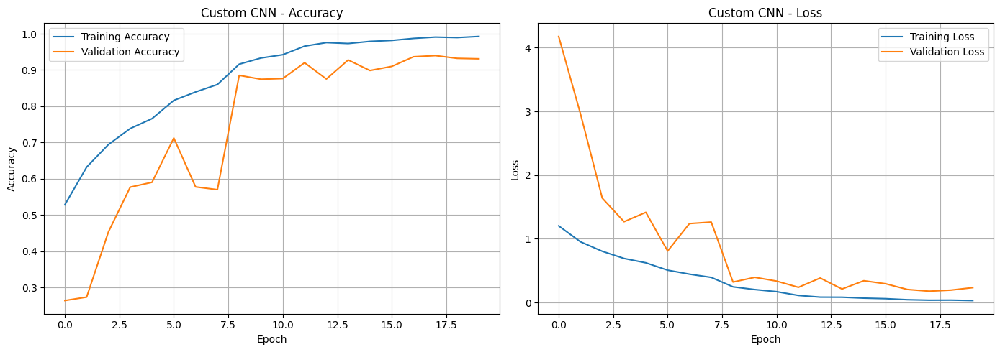

In [ ]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
BEST_CNN_PATH = os.path.join(
    BASE_PATH, "models", "custom_cnn_best.keras"
)

# Load the best saved model
custom_cnn = keras.models.load_model(BEST_CNN_PATH)

print("Model loaded successfully.")
print(f"Model name: {custom_cnn.name}")
print(f"Total parameters: {custom_cnn.count_params():,}")

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_custom_cnn.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    history_custom_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Custom CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_custom_cnn.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    history_custom_cnn.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Custom CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
MODEL_DIR = os.path.join(BASE_PATH, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

keras.backend.clear_session()

# Load pretrained MobileNetV2
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build classification model
inputs = keras.Input(shape=(224, 224, 3))

# Our dataset images are scaled to [0, 1].
# MobileNetV2 preprocessing converts them to [-1, 1].
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)

mobilenet_model = keras.Model(
    inputs,
    outputs,
    name="MobileNetV2_Oral_Disease"
)

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

print("MobileNetV2 model is ready.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Oral_Disease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

MobileNetV2 model is ready.


In [ ]:
import os
from tensorflow import keras

BEST_MOBILENET_PATH = os.path.join(
    MODEL_DIR, "mobilenetv2_best.keras"
)

mobilenet_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=BEST_MOBILENET_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=mobilenet_callbacks,
    verbose=1
)

print("\nBest model saved at:", BEST_MOBILENET_PATH)
print(
    "Best validation accuracy:",
    round(max(history_mobilenet.history["val_accuracy"]) * 100, 2),
    "%"
)
print("Epochs completed:", len(history_mobilenet.history["loss"]))

Epoch 1/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.5535 - loss: 1.2113
Epoch 1: val_loss improved from None to 0.54662, saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/mobilenetv2_best.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 45s 142ms/step - accuracy: 0.6702 - loss: 0.8862 - val_accuracy: 0.7915 - val_loss: 0.5466 - learning_rate: 0.0010
Epoch 2/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8055 - loss: 0.5141
Epoch 2: val_loss improved from 0.54662 to 0.42285, saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/mobilenetv2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/mobilenetv2_best.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 20s 91ms/step - accuracy: 0.8155 - loss: 0.4934 - val_accuracy: 0.8422 - val_loss: 0.4228 - le

In [ ]:
import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
MODEL_DIR = os.path.join(BASE_PATH, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

keras.backend.clear_session()

# Load pretrained EfficientNetB0
base_model_eff = keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model_eff.trainable = False

# Build classification model
inputs = keras.Input(shape=(224, 224, 3))

# EfficientNetB0 includes its own input rescaling.
# Our input images are already scaled to [0, 1].
x = base_model_eff(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    6,
    activation="softmax"
)(x)

efficientnet_model = keras.Model(
    inputs,
    outputs,
    name="EfficientNetB0_Oral_Disease"
)

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

print("EfficientNetB0 model is ready.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_Oral_Disease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

EfficientNetB0 model is ready.


In [ ]:
import os
from tensorflow import keras

BEST_EFFICIENTNET_PATH = os.path.join(
    MODEL_DIR, "efficientnetb0_best.keras"
)

efficientnet_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=BEST_EFFICIENTNET_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=efficientnet_callbacks,
    verbose=1
)

print("\nBest model saved at:", BEST_EFFICIENTNET_PATH)

print(
    "Best validation accuracy:",
    round(
        max(history_efficientnet.history["val_accuracy"]) * 100,
        2
    ),
    "%"
)

print(
    "Best validation loss:",
    round(
        min(history_efficientnet.history["val_loss"]),
        4
    )
)

print(
    "Epochs completed:",
    len(history_efficientnet.history["loss"])
)

Epoch 1/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.2549 - loss: 1.7025
Epoch 1: val_loss improved from None to 1.69937, saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/efficientnetb0_best.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 71s 199ms/step - accuracy: 0.2553 - loss: 1.6871 - val_accuracy: 0.2636 - val_loss: 1.6994 - learning_rate: 0.0010
Epoch 2/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.2494 - loss: 1.6775
Epoch 2: val_loss did not improve from 1.69937
224/224 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step - accuracy: 0.2468 - loss: 1.6836 - val_accuracy: 0.2395 - val_loss: 1.7140 - learning_rate: 0.0010
Epoch 3/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.2486 - loss: 1.6878
Epoch 3: val_loss did not improve from 1.69937

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00050000002374872

In [ ]:
import tensorflow as tf
from tensorflow import keras

print("Input batch range:")
for images, labels in train_ds.take(1):
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))

print("\nEfficientNetB0 internal preprocessing layers:")

for layer in base_model_eff.layers[:10]:
    print(
        layer.name,
        "|",
        layer.__class__.__name__,
        "|",
        getattr(layer, "scale", None),
        "|",
        getattr(layer, "offset", None)
    )

print("\nEfficientNetB0 input shape:", base_model_eff.input_shape)

Input batch range:
Minimum pixel value: 0.0
Maximum pixel value: 1.0

EfficientNetB0 internal preprocessing layers:
input_layer | InputLayer | None | None
rescaling | Rescaling | 0.00392156862745098 | 0.0
normalization | Normalization | None | None
rescaling_1 | Rescaling | [2.0896918976428642, 2.1128856368212916, 2.1081851067789197] | 0.0
stem_conv_pad | ZeroPadding2D | None | None
stem_conv | Conv2D | None | None
stem_bn | BatchNormalization | True | None
stem_activation | Activation | None | None
block1a_dwconv | DepthwiseConv2D | None | None
block1a_bn | BatchNormalization | True | None

EfficientNetB0 input shape: (None, 224, 224, 3)


In [ ]:
import tensorflow as tf
import numpy as np

# Get one batch
for images, labels in train_ds.take(1):
    sample_images = images[:8]
    sample_labels = labels[:8]

# Check raw pretrained backbone output
features = base_model_eff(sample_images, training=False)

print("Input range:")
print("Min:", float(tf.reduce_min(sample_images)))
print("Max:", float(tf.reduce_max(sample_images)))

print("\nBackbone output:")
print("Shape:", features.shape)
print("Min:", float(tf.reduce_min(features)))
print("Max:", float(tf.reduce_max(features)))
print("Mean:", float(tf.reduce_mean(features)))
print("Std:", float(tf.math.reduce_std(features)))

# Check classification probabilities
probabilities = efficientnet_model.predict(
    sample_images,
    verbose=0
)

print("\nPredicted probabilities for 8 images:")
print(np.round(probabilities, 3))

print("\nPredicted class indices:")
print(np.argmax(probabilities, axis=1))

print("\nActual class indices:")
print(sample_labels.numpy())

Input range:
Min: 0.0
Max: 1.0

Backbone output:
Shape: (8, 7, 7, 1280)
Min: -0.27846455574035645
Max: 9.60748291015625
Mean: -0.10493572056293488
Std: 0.4587031304836273

Predicted probabilities for 8 images:
[[0.038 0.244 0.119 0.121 0.284 0.194]
 [0.038 0.244 0.119 0.121 0.284 0.194]
 [0.038 0.244 0.119 0.121 0.283 0.194]
 [0.038 0.244 0.119 0.122 0.282 0.194]
 [0.038 0.244 0.119 0.121 0.284 0.194]
 [0.038 0.244 0.119 0.121 0.284 0.194]
 [0.038 0.245 0.118 0.121 0.284 0.194]
 [0.037 0.245 0.118 0.121 0.285 0.194]]

Predicted class indices:
[4 4 4 4 4 4 4 4]

Actual class indices:
[4 1 0 5 5 1 4 4]


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Load pretrained EfficientNetB0
base_model_eff_fixed = keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers for initial training
base_model_eff_fixed.trainable = False

# Build corrected model
inputs = keras.Input(shape=(224, 224, 3))

# Dataset images are in [0, 1].
# Convert them to [0, 255] before EfficientNet's internal preprocessing.
x = layers.Rescaling(255.0, name="input_rescaling")(inputs)

x = base_model_eff_fixed(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)

efficientnet_model_fixed = keras.Model(
    inputs,
    outputs,
    name="EfficientNetB0_Oral_Disease_Fixed"
)

efficientnet_model_fixed.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model_fixed.summary()

Model: "EfficientNetB0_Oral_Disease_Fixed"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_rescaling (Rescaling)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
for images, labels in train_ds.take(1):
    sample_images = images[:8]

features_fixed = base_model_eff_fixed(
    layers.Rescaling(255.0)(sample_images),
    training=False
)

print("Feature mean:", float(tf.reduce_mean(features_fixed)))
print("Feature std:", float(tf.math.reduce_std(features_fixed)))

probabilities_fixed = efficientnet_model_fixed.predict(
    sample_images,
    verbose=0
)

print("\nPredicted probabilities:")
print(probabilities_fixed.round(3))

print("\nPredicted classes:")
print(probabilities_fixed.argmax(axis=1))

Feature mean: 0.11655294895172119
Feature std: 0.80277419090271

Predicted probabilities:
[[0.04  0.085 0.028 0.347 0.447 0.052]
 [0.075 0.063 0.079 0.343 0.361 0.08 ]
 [0.1   0.13  0.151 0.2   0.283 0.136]
 [0.106 0.091 0.188 0.256 0.209 0.15 ]
 [0.037 0.157 0.08  0.155 0.424 0.147]
 [0.192 0.085 0.107 0.331 0.208 0.078]
 [0.088 0.089 0.05  0.374 0.285 0.114]
 [0.088 0.068 0.137 0.428 0.157 0.122]]

Predicted classes:
[4 4 4 3 4 3 3 3]


In [ ]:
import os
from tensorflow import keras

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
MODEL_DIR = os.path.join(BASE_PATH, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    MODEL_DIR,
    "efficientnetb0_fixed_best.keras"
)

callbacks_eff_fixed = [
    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_eff_fixed = efficientnet_model_fixed.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_eff_fixed,
    verbose=1
)

Epoch 1/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.5748 - loss: 1.0753
Epoch 1: val_loss improved from None to 0.53040, saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/efficientnetb0_fixed_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/efficientnetb0_fixed_best.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 60s 175ms/step - accuracy: 0.6984 - loss: 0.8139 - val_accuracy: 0.8245 - val_loss: 0.5304 - learning_rate: 0.0010
Epoch 2/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.8228 - loss: 0.5289
Epoch 2: val_loss improved from 0.53040 to 0.42004, saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/efficientnetb0_fixed_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/efficientnetb0_fixed_best.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 53s 89ms/step - accuracy: 0.8254 - loss: 0.5030 - val_acc

In [ ]:
import numpy as np

best_val_accuracy = max(
    history_eff_fixed.history["val_accuracy"]
)

best_val_loss = min(
    history_eff_fixed.history["val_loss"]
)

best_accuracy_epoch = (
    np.argmax(history_eff_fixed.history["val_accuracy"]) + 1
)

best_loss_epoch = (
    np.argmin(history_eff_fixed.history["val_loss"]) + 1
)

print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")
print(f"Epoch of Best Accuracy: {best_accuracy_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Epoch of Best Loss: {best_loss_epoch}")
print(f"Saved Model: {checkpoint_path}")

Best Validation Accuracy: 0.9328
Epoch of Best Accuracy: 15
Best Validation Loss: 0.2040
Epoch of Best Loss: 18
Saved Model: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/efficientnetb0_fixed_best.keras


In [ ]:
import os
from tensorflow import keras

MODEL_DIR = os.path.join(BASE_PATH, "models")

custom_cnn_best = keras.models.load_model(
    os.path.join(MODEL_DIR, "custom_cnn_best.keras")
)

mobilenet_best = keras.models.load_model(
    os.path.join(MODEL_DIR, "mobilenetv2_best.keras")
)

efficientnet_best = keras.models.load_model(
    os.path.join(MODEL_DIR, "efficientnetb0_fixed_best.keras")
)

models_to_compare = {
    "Custom CNN": custom_cnn_best,
    "MobileNetV2": mobilenet_best,
    "EfficientNetB0": efficientnet_best
}

print("All three models loaded successfully.")

All three models loaded successfully.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

models_to_compare = {
    "Custom CNN": custom_cnn_best,
    "MobileNetV2": mobilenet_best,
    "EfficientNetB0": efficientnet_best
}

# Extract true labels from validation dataset
y_true = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

results = []
reports = {}

for model_name, model in models_to_compare.items():
    print(f"Evaluating {model_name}...")

    # Predict validation classes
    y_prob = model.predict(val_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    # Calculate metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    })

    reports[model_name] = classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        zero_division=0,
        output_dict=True
    )

comparison_df = pd.DataFrame(results)

print("\n=== Model Comparison on Validation Set ===")
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision (Macro)": "{:.4f}",
        "Recall (Macro)": "{:.4f}",
        "F1-score (Macro)": "{:.4f}"
    })
)

Evaluating Custom CNN...
Evaluating MobileNetV2...
Evaluating EfficientNetB0...

=== Model Comparison on Validation Set ===


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Custom CNN,0.9398,0.9179,0.9181,0.9168
1,MobileNetV2,0.9011,0.8773,0.8893,0.8818
2,EfficientNetB0,0.9322,0.9309,0.9102,0.9179


In [ ]:
for model_name, report in reports.items():
    print(f"\n{'=' * 60}")
    print(f"Classification Report: {model_name}")
    print("=" * 60)

    report_df = pd.DataFrame(report).T

    display(
        report_df.loc[
            CLASS_NAMES,
            ["precision", "recall", "f1-score", "support"]
        ].style.format({
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1-score": "{:.4f}",
            "support": "{:.0f}"
        })
    )


Classification Report: Custom CNN


,precision,recall,f1-score,support
Calculus,0.7396,0.8452,0.7889,84
Caries,0.9167,0.9603,0.9380,378
Gingivitis,0.9421,0.8524,0.8950,210
Hypodontia,0.9733,0.9010,0.9357,202
Mouth_Ulcer,0.9809,0.9880,0.9844,416
Tooth_Discoloration,0.9552,0.9618,0.9585,288



Classification Report: MobileNetV2


,precision,recall,f1-score,support
Calculus,0.7188,0.8214,0.7667,84
Caries,0.9060,0.8413,0.8724,378
Gingivitis,0.9211,0.8333,0.8750,210
Hypodontia,0.9019,0.9554,0.9279,202
Mouth_Ulcer,0.9758,0.9712,0.9735,416
Tooth_Discoloration,0.8403,0.9132,0.8752,288



Classification Report: EfficientNetB0


,precision,recall,f1-score,support
Calculus,0.9538,0.7381,0.8322,84
Caries,0.9125,0.9101,0.9113,378
Gingivitis,0.8904,0.9667,0.9269,210
Hypodontia,0.9320,0.9505,0.9412,202
Mouth_Ulcer,0.9853,0.9688,0.9770,416
Tooth_Discoloration,0.9113,0.9271,0.9191,288


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.arange(len(CLASS_NAMES))

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["Label"].to_numpy()
)

class_weights = {
    int(class_index): float(weight)
    for class_index, weight in zip(classes, class_weights_array)
}

print("Class weights:")
for class_index, weight in class_weights.items():
    print(f"{CLASS_NAMES[class_index]}: {weight:.3f}")

Class weights:
Calculus: 3.954
Caries: 0.662
Gingivitis: 1.447
Hypodontia: 1.400
Mouth_Ulcer: 0.617
Tooth_Discoloration: 0.826


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
import os

# Create a new model with the same architecture, initialized from scratch
weighted_cnn = keras.models.clone_model(custom_cnn_best)

# Compile the new model
weighted_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best checkpoint separately
weighted_checkpoint = os.path.join(
    MODEL_DIR, "custom_cnn_weighted_best.keras"
)

weighted_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=weighted_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Train with class weights
weighted_history = weighted_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=weighted_callbacks
)

Epoch 1/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.3844 - loss: 1.6096
Epoch 1: val_loss improved from None to 4.01320, saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_weighted_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_weighted_best.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 36s 114ms/step - accuracy: 0.4555 - loss: 1.3625 - val_accuracy: 0.2807 - val_loss: 4.0132 - learning_rate: 0.0010
Epoch 2/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.5429 - loss: 1.0773
Epoch 2: val_loss improved from 4.01320 to 2.49729, saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_weighted_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_weighted_best.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 20s 89ms/step - accuracy: 0.5711 - loss: 1.0493 - val_accuracy

KeyboardInterrupt: 

In [ ]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

clean_df = pd.read_csv(
    os.path.join(BASE_PATH, "clean_image_manifest.csv")
)

excluded_df = pd.read_csv(
    os.path.join(BASE_PATH, "excluded_image_manifest.csv")
)

print("Clean manifest shape:", clean_df.shape)
print("Excluded manifest shape:", excluded_df.shape)

print("\nClean manifest columns:")
print(clean_df.columns.tolist())

print("\nExcluded manifest columns:")
print(excluded_df.columns.tolist())

print("\nClean images by class:")
print(clean_df["Class"].value_counts())

print("\nExcluded images by class:")
print(excluded_df["Class"].value_counts())

Clean manifest shape: (10264, 6)
Excluded manifest shape: (2056, 6)

Clean manifest columns:
['SHA256', 'Class', 'Source_Folder', 'Filename', 'Path', 'Copies_Found']

Excluded manifest columns:
['SHA256', 'Class', 'Source_Folder', 'Filename', 'Path', 'Reason']

Clean images by class:
Class
Mouth_Ulcer            2784
Caries                 2573
Tooth_Discoloration    2007
Gingivitis             1236
Hypodontia             1215
Calculus                449
Name: count, dtype: int64

Excluded images by class:
Class
Gingivitis             1113
Calculus                847
Hypodontia               36
Caries                   28
Mouth_Ulcer              22
Tooth_Discoloration      10
Name: count, dtype: int64


In [ ]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

excluded_df = pd.read_csv(
    os.path.join(BASE_PATH, "excluded_image_manifest.csv")
)

# Count exclusion reasons by class
reason_summary = pd.crosstab(
    excluded_df["Class"],
    excluded_df["Reason"]
)

print(reason_summary.to_string())

print("\n\nDetailed exclusion reasons:")
print(
    excluded_df.groupby(["Class", "Reason"])
    .size()
    .reset_index(name="Count")
    .sort_values(["Class", "Count"], ascending=[True, False])
    .to_string(index=False)
)

Reason               Exact duplicate across different classes  Exact duplicate within the same class
Class                                                                                               
Calculus                                                  731                                    116
Caries                                                     14                                     14
Gingivitis                                                734                                    379
Hypodontia                                                 27                                      9
Mouth_Ulcer                                                 0                                     22
Tooth_Discoloration                                         4                                      6


Detailed exclusion reasons:
              Class                                   Reason  Count
           Calculus Exact duplicate across different classes    731
           Calculus    Exa

In [ ]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

clean_df = pd.read_csv(
    os.path.join(BASE_PATH, "clean_image_manifest.csv")
)

excluded_df = pd.read_csv(
    os.path.join(BASE_PATH, "excluded_image_manifest.csv")
)

# Find hashes appearing in both manifests
clean_hashes = set(clean_df["SHA256"].dropna())
excluded_hashes = set(excluded_df["SHA256"].dropna())

shared_hashes = clean_hashes & excluded_hashes

print("Unique hashes in clean manifest:", len(clean_hashes))
print("Unique hashes in excluded manifest:", len(excluded_hashes))
print("Hashes appearing in both manifests:", len(shared_hashes))

# Inspect cross-class duplicates
cross_class = excluded_df[
    excluded_df["Reason"].eq(
        "Exact duplicate across different classes"
    )
].copy()

# Show class labels and paths for each shared hash
review = (
    pd.concat([
        clean_df[["SHA256", "Class", "Path"]].assign(Status="Kept"),
        cross_class[["SHA256", "Class", "Path"]].assign(Status="Excluded")
    ])
    .drop_duplicates()
    .sort_values(["SHA256", "Class", "Status"])
)

review = review[review["SHA256"].isin(shared_hashes)]

print("\nSample cross-class duplicate records:")
display(review.head(30))

# Save the review table
review_path = os.path.join(
    BASE_PATH, "cross_class_duplicate_review.csv"
)

review.to_csv(review_path, index=False)

print("\nSaved review file:", review_path)

Unique hashes in clean manifest: 10264
Unique hashes in excluded manifest: 775
Hashes appearing in both manifests: 383

Sample cross-class duplicate records:


,SHA256,Class,Path,Status
3776,019112e7eeabeef8d3ae49dc18f84a27e405d0206f24a3...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept
153,01acaa4a0fd9a054cf6e78b75a7274c2de53a8fb0b4a72...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept
3445,021ef5fb9eea74f3a7282418420eaebab518f05210d7fa...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept
173,0221c597827c5c4fd886d5c36bc2f2369437cecc64db96...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept
18,025fd5ba6125aad56089490e7446936e4e27bcaf54cc8c...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept
3181,030a928fdc8c31b23fce488a4c293be7d2026684e66314...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept
3945,053c1d9d5d84c1de421d942eec3fe1a65d0b36717d5ea1...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept
3784,05e350a8fd5a6af78b8d22d1fb999abaad0008a1682f32...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept
281,06159d6fd635a2855c98b007eced05846dda00e75e6589...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept
412,0678611300e411367421a2c25ab5c1eda69ed072bbe6f6...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Kept



Saved review file: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/cross_class_duplicate_review.csv


In [ ]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

clean_df = pd.read_csv(
    os.path.join(BASE_PATH, "clean_image_manifest.csv")
)

excluded_df = pd.read_csv(
    os.path.join(BASE_PATH, "excluded_image_manifest.csv")
)

# Combine all records
all_records = pd.concat([
    clean_df[["SHA256", "Class", "Path"]].assign(Status="Kept"),
    excluded_df[["SHA256", "Class", "Path", "Reason"]]
        .assign(Status="Excluded")
], ignore_index=True)

# Count distinct class labels for each image hash
hash_summary = (
    all_records.groupby("SHA256")
    .agg(
        Classes=("Class", lambda x: sorted(set(x))),
        Class_Count=("Class", "nunique"),
        Record_Count=("Class", "size")
    )
    .reset_index()
)

# Images associated with more than one class
cross_class_hashes = hash_summary[
    hash_summary["Class_Count"] > 1
].copy()

print("Total unique image hashes:", hash_summary.shape[0])
print("Hashes associated with multiple classes:", len(cross_class_hashes))

print("\nClass combinations:")
print(
    cross_class_hashes["Classes"]
    .apply(lambda x: " + ".join(x))
    .value_counts()
    .to_string()
)

print("\nSample:")
display(cross_class_hashes.head(20))

Total unique image hashes: 10656
Hashes associated with multiple classes: 392

Class combinations:
Classes
Calculus + Gingivitis                                       353
Gingivitis + Hypodontia                                       9
Calculus + Hypodontia                                         9
Calculus + Gingivitis + Hypodontia                            8
Calculus + Caries + Gingivitis                                4
Calculus + Caries                                             3
Caries + Gingivitis                                           3
Calculus + Gingivitis + Tooth_Discoloration                   2
Calculus + Gingivitis + Hypodontia + Tooth_Discoloration      1

Sample:


,SHA256,Classes,Class_Count,Record_Count
59,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,"[Calculus, Gingivitis]",2,3
87,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,"[Calculus, Gingivitis]",2,8
122,03607184a76e9c3f1ec3de4dbebb8b23e8261fab844c93...,"[Calculus, Gingivitis]",2,5
142,03e91152855858e48eb910973d0ee7bf869ab537edd349...,"[Calculus, Gingivitis]",2,4
167,049142cdb2627190ce10a75be2492cadfdaae5b80a71fa...,"[Calculus, Gingivitis]",2,2
197,0530d30271fb7dbb62aef0e6ed3a72f53e9eec00a1d310...,"[Calculus, Gingivitis]",2,2
269,06dd0f0ee8501c7e7a6c71b37e493167cd647fc3b59aff...,"[Calculus, Gingivitis]",2,2
272,06e2a8c52ee91ed0661e20e3b3a60f1a1f03bc03742ea0...,"[Calculus, Gingivitis]",2,3
282,070444449ec53bf08675b52caf0ddb8268e8b65445ae17...,"[Calculus, Gingivitis]",2,2
314,07e7a0e2e7bdd8c70f87a356112cbc18f466982c803acf...,"[Calculus, Gingivitis]",2,4


Calculus + Gingivitis duplicate groups: 368

Image 1
Classes: ['Calculus', 'Gingivitis']
Records: 3


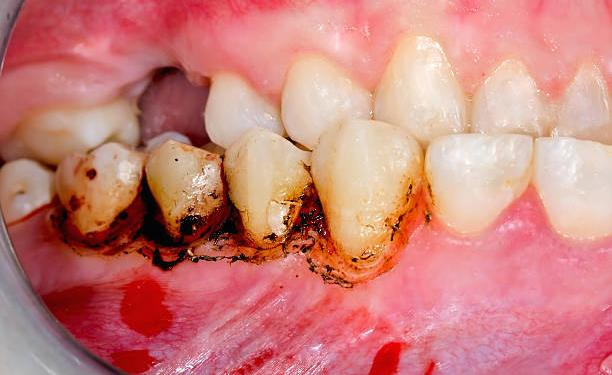

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
2,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 2
Classes: ['Calculus', 'Gingivitis']
Records: 8


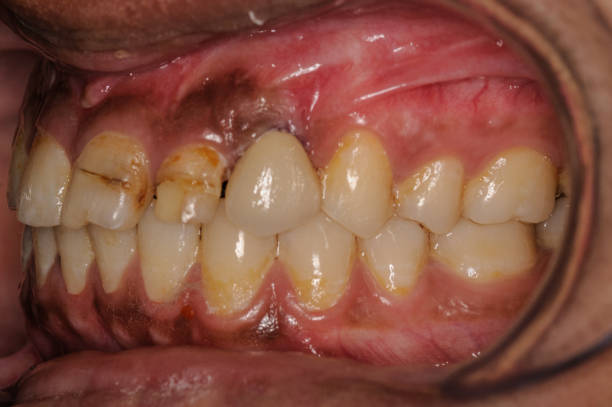

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
2,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
3,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
4,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
5,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
6,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
7,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 3
Classes: ['Calculus', 'Gingivitis']
Records: 5


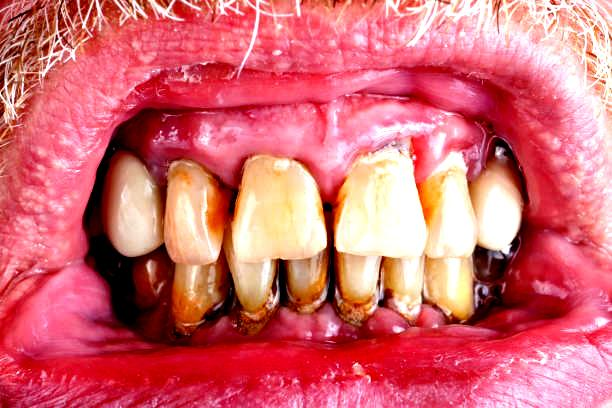

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
2,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
3,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
4,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 4
Classes: ['Calculus', 'Gingivitis']
Records: 4


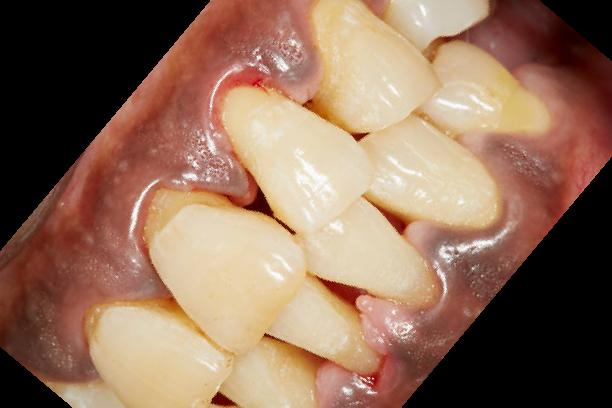

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
2,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
3,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 5
Classes: ['Calculus', 'Gingivitis']
Records: 2


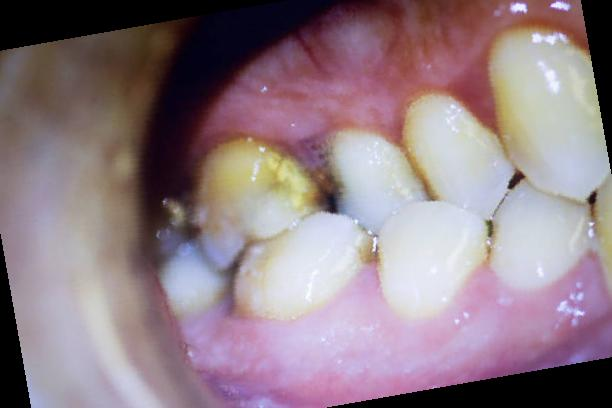

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 6
Classes: ['Calculus', 'Gingivitis']
Records: 2


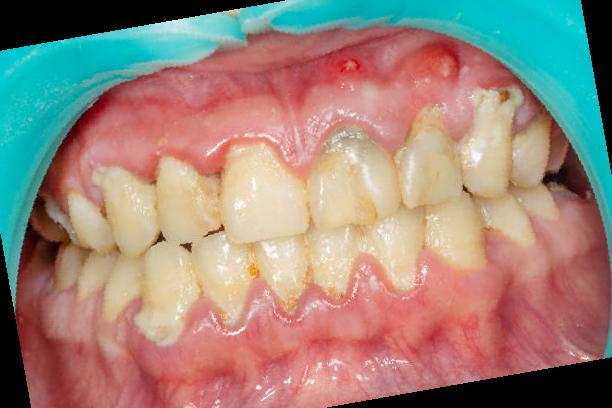

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 7
Classes: ['Calculus', 'Gingivitis']
Records: 2


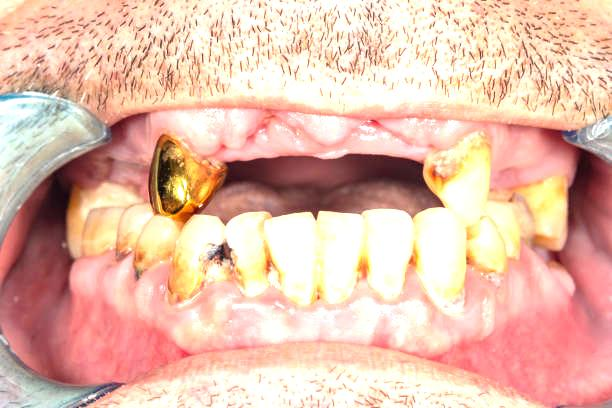

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 8
Classes: ['Calculus', 'Gingivitis']
Records: 3


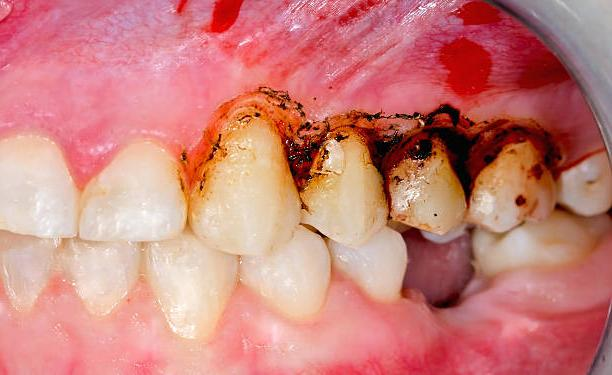

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
2,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 9
Classes: ['Calculus', 'Gingivitis']
Records: 2


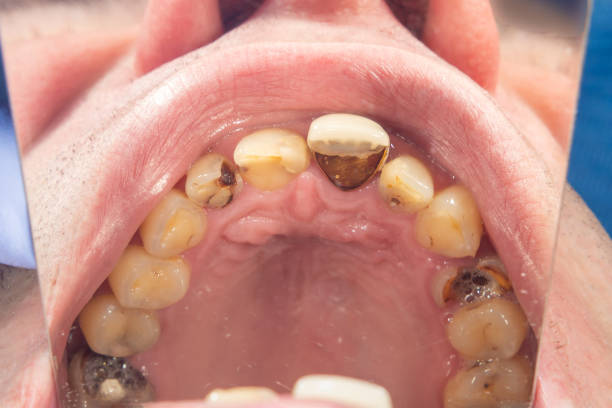

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 10
Classes: ['Calculus', 'Gingivitis']
Records: 4


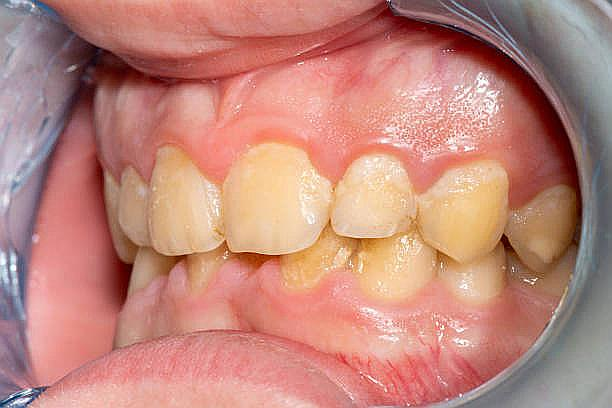

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
2,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
3,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 11
Classes: ['Calculus', 'Gingivitis']
Records: 5


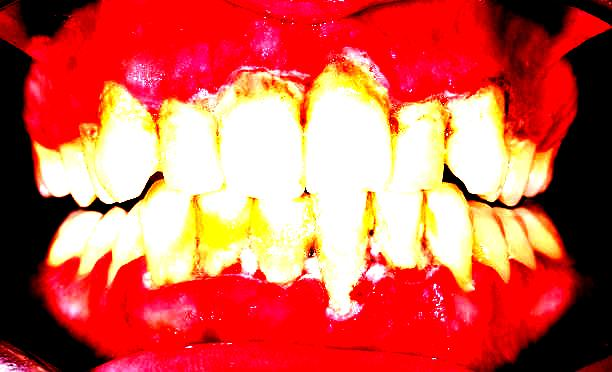

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
2,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
3,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
4,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...



Image 12
Classes: ['Calculus', 'Gingivitis']
Records: 2


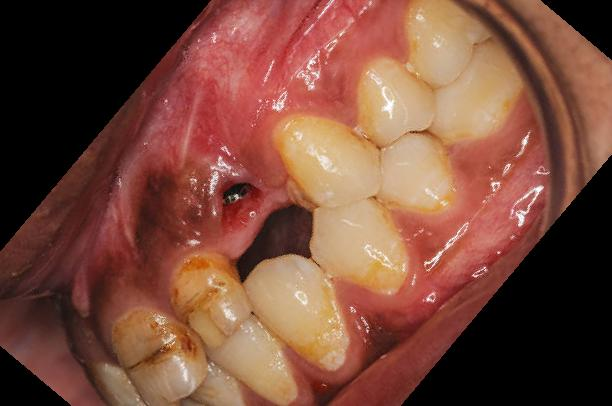

,Class,Status,Path
0,Calculus,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...
1,Gingivitis,Excluded,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...


In [ ]:
import os
import pandas as pd
from IPython.display import display, Image

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

clean_df = pd.read_csv(
    os.path.join(BASE_PATH, "clean_image_manifest.csv")
)

excluded_df = pd.read_csv(
    os.path.join(BASE_PATH, "excluded_image_manifest.csv")
)

# Combine retained and excluded records
all_records = pd.concat([
    clean_df[["SHA256", "Class", "Path"]].assign(Status="Kept"),
    excluded_df[["SHA256", "Class", "Path", "Reason"]]
        .assign(Status="Excluded")
], ignore_index=True)

# Find images appearing in both Calculus and Gingivitis
target_classes = {"Calculus", "Gingivitis"}

hash_classes = (
    all_records.groupby("SHA256")["Class"]
    .apply(set)
)

target_hashes = hash_classes[
    hash_classes.apply(lambda classes: target_classes.issubset(classes))
].index.tolist()

print("Calculus + Gingivitis duplicate groups:", len(target_hashes))

# Select 12 groups for visual inspection
sample_hashes = target_hashes[:12]

for i, image_hash in enumerate(sample_hashes, start=1):
    records = all_records[all_records["SHA256"] == image_hash]

    # Display one copy of the exact image
    image_path = records.iloc[0]["Path"]

    print(f"\n{'=' * 50}")
    print(f"Image {i}")
    print("Classes:", sorted(records["Class"].unique()))
    print("Records:", len(records))

    if os.path.exists(image_path):
        display(Image(filename=image_path, width=350))
    else:
        print("Image file not found:", image_path)

    display(
        records[["Class", "Status", "Path"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )

In [ ]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

clean_df = pd.read_csv(
    os.path.join(BASE_PATH, "clean_image_manifest.csv")
)

excluded_df = pd.read_csv(
    os.path.join(BASE_PATH, "excluded_image_manifest.csv")
)

# Combine kept and excluded records
columns = ["SHA256", "Class", "Path", "Source_Folder", "Filename"]

all_records = pd.concat([
    clean_df[columns].assign(Status="Kept"),
    excluded_df[columns].assign(Status="Excluded")
], ignore_index=True)

# Find exact images associated with both classes
target_classes = {"Calculus", "Gingivitis"}

hash_classes = all_records.groupby("SHA256")["Class"].agg(
    lambda values: set(values)
)

target_hashes = hash_classes[
    hash_classes.apply(lambda classes: target_classes.issubset(classes))
].index

review_df = all_records[
    all_records["SHA256"].isin(target_hashes)
].copy()

# Keep all records so we can inspect the source and status
review_df = review_df.sort_values(
    ["SHA256", "Class", "Status"]
)

output_path = os.path.join(
    BASE_PATH,
    "Calculus_Gingivitis_Review.csv"
)

review_df.to_csv(output_path, index=False)

print("Unique overlapping images:", len(target_hashes))
print("Review records:", len(review_df))
print("\nRecords by class and status:")
print(pd.crosstab(review_df["Class"], review_df["Status"]))

print("\nReview file saved to:")
print(output_path)

display(review_df.head(15))

Unique overlapping images: 368
Review records: 1442

Records by class and status:
Status               Excluded
Class                        
Calculus                  701
Caries                      7
Gingivitis                721
Hypodontia                  9
Tooth_Discoloration         4

Review file saved to:
/content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Calculus_Gingivitis_Review.csv


,SHA256,Class,Path,Source_Folder,Filename,Status
11344,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Calculus,(804).jpg,Excluded
11345,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Gingivitis,(1379).jpg,Excluded
11346,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Gingivitis,(1491).jpg,Excluded
10405,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Calculus,(137).jpg,Excluded
10406,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Calculus,(58).jpg,Excluded
10407,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Calculus,(59).jpg,Excluded
10408,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Calculus,(92).jpg,Excluded
10409,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Calculus,(118).jpg,Excluded
10410,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Gingivitis,(240).jpg,Excluded
10411,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Gingivitis,(84).jpg,Excluded


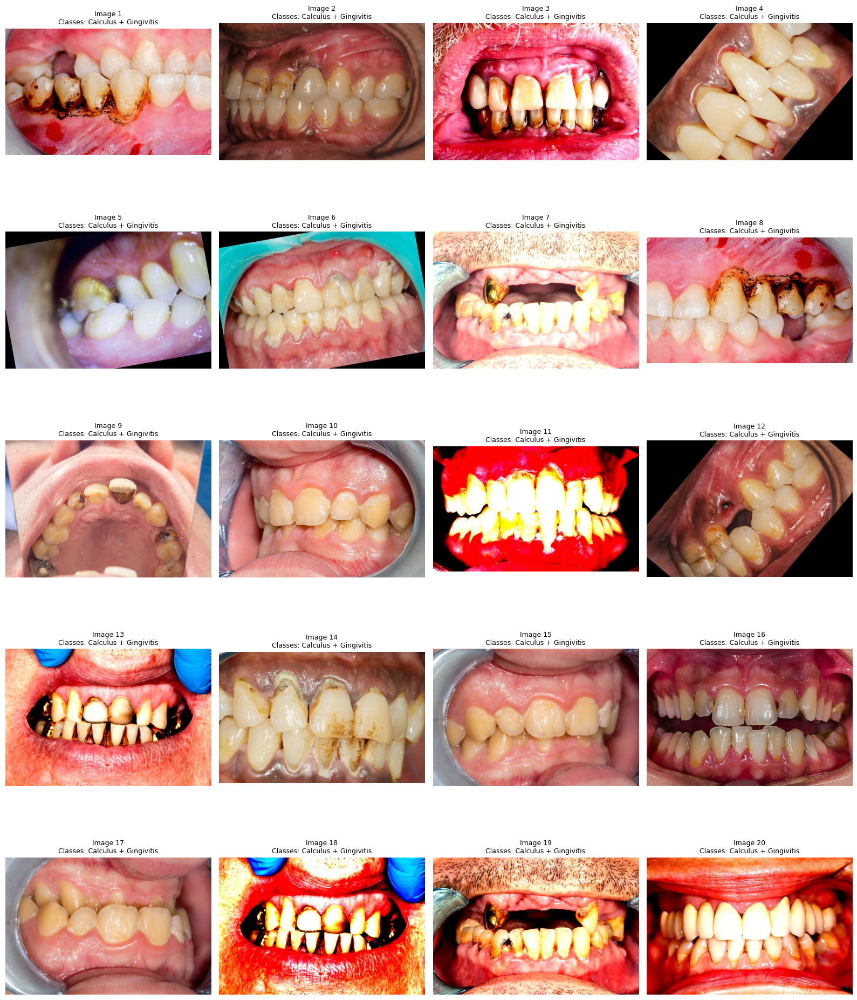

Displaying images 1 to 20
Total overlapping images: 368


In [ ]:
import os
import math
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

review_df = pd.read_csv(
    os.path.join(BASE_PATH, "Calculus_Gingivitis_Review.csv")
)

# One representative path per exact image hash and class
unique_records = (
    review_df.sort_values(["SHA256", "Class", "Status"])
    .drop_duplicates(["SHA256", "Class"])
    .copy()
)

# Show images associated with both Calculus and Gingivitis
class_sets = unique_records.groupby("SHA256")["Class"].agg(set)

target_hashes = class_sets[
    class_sets.apply(
        lambda classes: {"Calculus", "Gingivitis"}.issubset(classes)
    )
].index.tolist()

image_records = (
    unique_records[unique_records["SHA256"].isin(target_hashes)]
    .drop_duplicates("SHA256")
    .set_index("SHA256")
    .loc[target_hashes]
    .reset_index()
)

# Change this number to inspect another batch
BATCH_NUMBER = 1
BATCH_SIZE = 20

start = (BATCH_NUMBER - 1) * BATCH_SIZE
batch = image_records.iloc[start:start + BATCH_SIZE]

cols = 4
rows = math.ceil(len(batch) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax in axes:
    ax.axis("off")

for i, (_, row) in enumerate(batch.iterrows()):
    path = row["Path"]

    if os.path.exists(path):
        try:
            img = Image.open(path).convert("RGB")
            axes[i].imshow(img)
            axes[i].set_title(
                f"Image {start + i + 1}\n"
                f"Classes: Calculus + Gingivitis",
                fontsize=9
            )
            axes[i].axis("off")
        except Exception as e:
            axes[i].set_title(f"Image error: {e}", fontsize=8)

plt.tight_layout()
plt.show()

print(f"Displaying images {start + 1} to {start + len(batch)}")
print(f"Total overlapping images: {len(image_records)}")

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
CSV_PATH = os.path.join(BASE_PATH, "Calculus_Gingivitis_Review.csv")

df = pd.read_csv(CSV_PATH)

print("Columns:", df.columns.tolist())
display(df.head())

Columns: ['SHA256', 'Class', 'Path', 'Source_Folder', 'Filename', 'Status']


,SHA256,Class,Path,Source_Folder,Filename,Status
0,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Calculus,(804).jpg,Excluded
1,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Gingivitis,(1379).jpg,Excluded
2,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,Gingivitis,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Gingivitis,(1491).jpg,Excluded
3,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Calculus,(137).jpg,Excluded
4,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...,Calculus,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,Calculus,(58).jpg,Excluded



PAIR 1
SHA256: 019351da19b648d860dd4bb8bc00e978f2a39c9843c55f3c17b65b80e52e7c82
Calculus path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Calculus/Calculus/(804).jpg
Gingivitis path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Gingivitis/Gingivitis/(1379).jpg


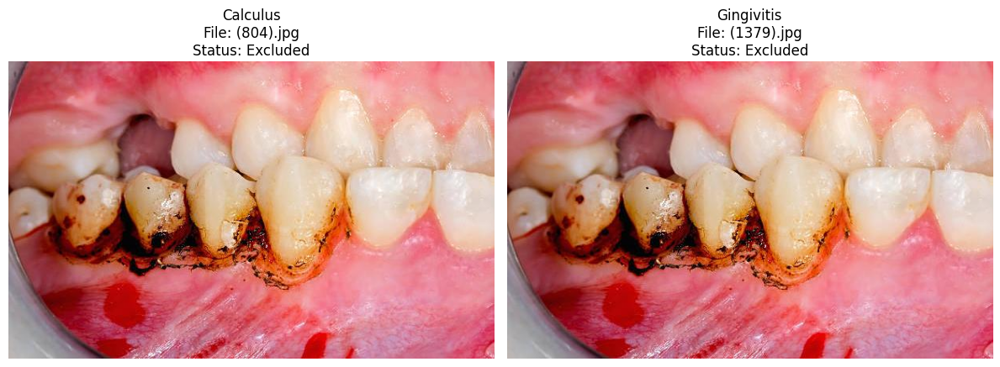


PAIR 2
SHA256: 02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13823d2bb7c4a8d0d8fc
Calculus path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Calculus/Calculus/(137).jpg
Gingivitis path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Gingivitis/Gingivitis/(240).jpg


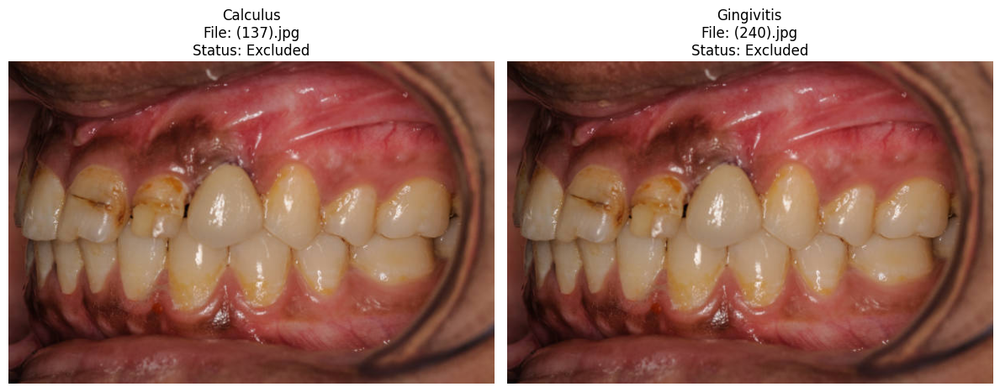


PAIR 3
SHA256: 03607184a76e9c3f1ec3de4dbebb8b23e8261fab844c93c2e9bdff763b13e0cd
Calculus path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Calculus/Calculus/(292).jpg
Gingivitis path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Gingivitis/Gingivitis/(638).jpg


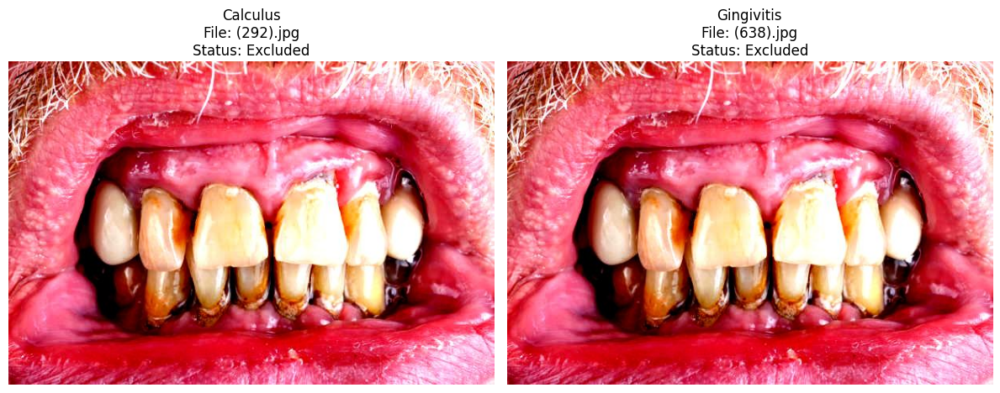


PAIR 4
SHA256: 03e91152855858e48eb910973d0ee7bf869ab537edd34937132924353e166c83
Calculus path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Calculus/Calculus/(1064).jpg
Gingivitis path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Gingivitis/Gingivitis/(1831).jpg


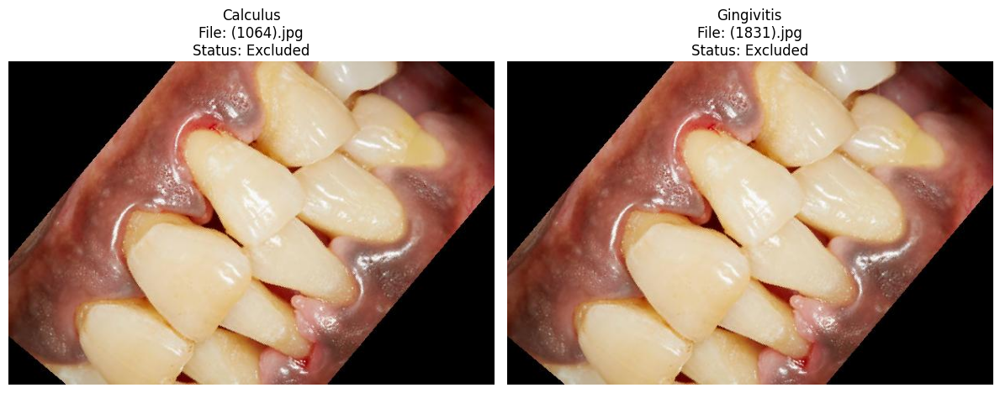

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
CSV_PATH = os.path.join(BASE_PATH, "Calculus_Gingivitis_Review.csv")

df = pd.read_csv(CSV_PATH)

# التأكد من أن الصور موجودة في الفئتين
classes_per_hash = df.groupby("SHA256")["Class"].apply(set)

valid_hashes = classes_per_hash[
    classes_per_hash.apply(
        lambda classes: {"Calculus", "Gingivitis"}.issubset(classes)
    )
].index

pairs_df = df[df["SHA256"].isin(valid_hashes)].copy()

# اختيار أول 4 مجموعات مختلفة من الصور المتطابقة
selected_hashes = list(valid_hashes[:4])

for i, image_hash in enumerate(selected_hashes, start=1):
    group = pairs_df[pairs_df["SHA256"] == image_hash]
    calculus_rows = group[group["Class"] == "Calculus"]
    gingivitis_rows = group[group["Class"] == "Gingivitis"]

    if calculus_rows.empty or gingivitis_rows.empty:
        continue

    calculus_row = calculus_rows.iloc[0]
    gingivitis_row = gingivitis_rows.iloc[0]

    print(f"\n{'='*70}")
    print(f"PAIR {i}")
    print(f"SHA256: {image_hash}")
    print(f"Calculus path: {calculus_row['Path']}")
    print(f"Gingivitis path: {gingivitis_row['Path']}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, row, class_name in [
        (axes[0], calculus_row, "Calculus"),
        (axes[1], gingivitis_row, "Gingivitis")
    ]:
        path = row["Path"]

        if os.path.isfile(path):
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(
                f"{class_name}\n"
                f"File: {row['Filename']}\n"
                f"Status: {row['Status']}"
            )
        else:
            ax.text(0.5, 0.5, "Image file not found",
                    ha="center", va="center")
            ax.set_title(class_name)

        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

files_to_check = [
    "clean_image_manifest.csv",
    "excluded_image_manifest.csv",
    "image_hash_manifest.csv",
    "image_similarity_groups.csv",
    "dataset_split_manifest.csv",
    "cross_class_duplicate_review.csv",
    "Calculus_Gingivitis_Review.csv",
]

for filename in files_to_check:
    path = os.path.join(BASE_PATH, filename)
    print(f"{'✅' if os.path.exists(path) else '❌'} {filename}")

✅ clean_image_manifest.csv
✅ excluded_image_manifest.csv
✅ image_hash_manifest.csv
✅ image_similarity_groups.csv
✅ dataset_split_manifest.csv
✅ cross_class_duplicate_review.csv
✅ Calculus_Gingivitis_Review.csv


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

print("Searching for saved models...\n")

for root, dirs, files in os.walk(BASE_PATH):
    # تجاهل مجلدات البيانات لتسريع البحث
    dirs[:] = [
        d for d in dirs
        if d not in ["Calculus", "Caries", "Gingivitis",
                     "Hypodontia", "Mouth_Ulcer",
                     "Tooth_Discoloration"]
    ]

    for file in files:
        if file.endswith((".keras", ".h5", ".pkl", ".joblib")):
            path = os.path.join(root, file)
            size_mb = os.path.getsize(path) / (1024 * 1024)

            print(f"Model: {file}")
            print(f"Path: {path}")
            print(f"Size: {size_mb:.2f} MB")
            print("-" * 60)

Searching for saved models...

Model: custom_cnn_best.keras
Path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_best.keras
Size: 4.92 MB
------------------------------------------------------------
Model: mobilenetv2_best.keras
Path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/mobilenetv2_best.keras
Size: 9.27 MB
------------------------------------------------------------
Model: efficientnetb0_best.keras
Path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/efficientnetb0_best.keras
Size: 16.34 MB
------------------------------------------------------------
Model: efficientnetb0_fixed_best.keras
Path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/efficientnetb0_fixed_best.keras
Size: 16.35 MB
------------------------------------------------------------
Model: custom_cnn_weighted_best.keras
Path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/models/custom_cnn_weighted_best.keras
Size

Duplicate groups found: 368

Class: Calculus
Filename: (137).jpg
Path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Calculus/Calculus/(137).jpg

Class: Gingivitis
Filename: (240).jpg
Path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Gingivitis/Gingivitis/(240).jpg


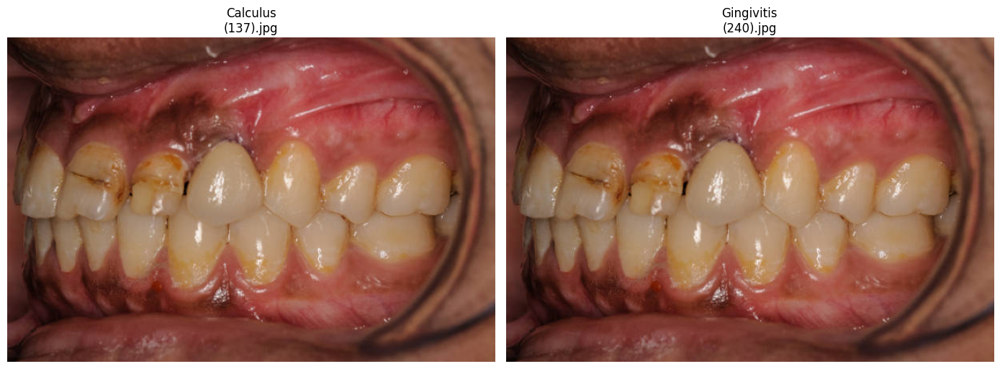


SHA256: 02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13823d2bb7c4a8d0d8fc


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
REVIEW_FILE = os.path.join(BASE_PATH, "Calculus_Gingivitis_Review.csv")

review_df = pd.read_csv(REVIEW_FILE)

# البحث عن الصور الموجودة في الفئتين معًا
cross_class_hashes = (
    review_df.groupby("SHA256")["Class"]
    .agg(lambda x: set(x.dropna().astype(str)))
)

valid_hashes = [
    sha for sha, classes in cross_class_hashes.items()
    if {"Calculus", "Gingivitis"}.issubset(classes)
]

print(f"Duplicate groups found: {len(valid_hashes)}")

if len(valid_hashes) < 2:
    print("لم يتم العثور على زوج ثانٍ.")
else:
    target_hash = valid_hashes[1]

    pair = review_df[
        (review_df["SHA256"] == target_hash)
        & (review_df["Class"].isin(["Calculus", "Gingivitis"]))
    ]

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    for ax, class_name in zip(axes, ["Calculus", "Gingivitis"]):
        rows = pair[pair["Class"] == class_name]

        ax.axis("off")

        if rows.empty:
            ax.set_title(f"{class_name}: image not found")
            continue

        row = rows.iloc[0]
        image_path = str(row["Path"])

        ax.set_title(f"{class_name}\n{row['Filename']}")

        print(f"\nClass: {class_name}")
        print(f"Filename: {row['Filename']}")
        print(f"Path: {image_path}")

        if os.path.exists(image_path):
            with Image.open(image_path) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.text(
                0.5, 0.5,
                f"Image not found:\n{image_path}",
                ha="center",
                va="center"
            )

    plt.tight_layout()
    plt.show()

    print("\nSHA256:", target_hash)


Class: Calculus
Filename: (292).jpg
Path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Calculus/Calculus/(292).jpg

Class: Gingivitis
Filename: (638).jpg
Path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/Gingivitis/Gingivitis/(638).jpg


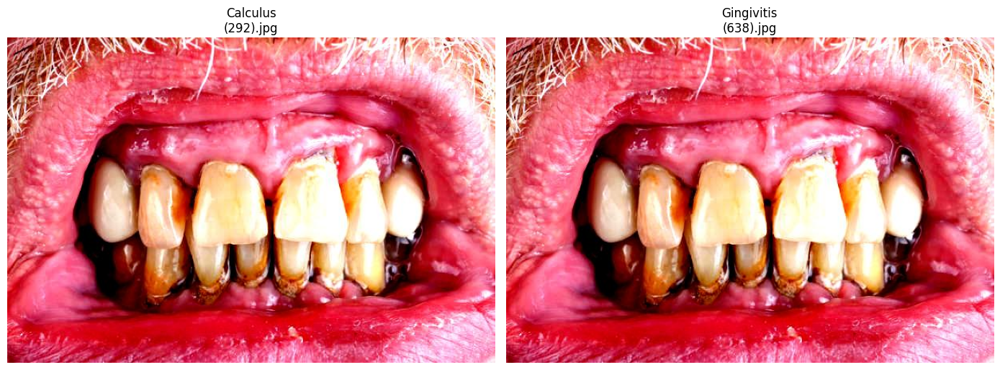


SHA256: 03607184a76e9c3f1ec3de4dbebb8b23e8261fab844c93c2e9bdff763b13e0cd


In [ ]:
# عرض الزوج الثالث من الصور المتطابقة بين Calculus وGingivitis

target_hash = valid_hashes[2]

pair = review_df[
    (review_df["SHA256"] == target_hash)
    & (review_df["Class"].isin(["Calculus", "Gingivitis"]))
]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, class_name in zip(axes, ["Calculus", "Gingivitis"]):
    rows = pair[pair["Class"] == class_name]
    ax.axis("off")

    if rows.empty:
        ax.set_title(f"{class_name}: image not found")
        continue

    row = rows.iloc[0]
    image_path = str(row["Path"])

    print(f"\nClass: {class_name}")
    print(f"Filename: {row['Filename']}")
    print(f"Path: {image_path}")

    ax.set_title(f"{class_name}\n{row['Filename']}")

    if os.path.exists(image_path):
        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))
    else:
        ax.set_title(f"{class_name}: image not found")
        print("Image file does not exist.")

plt.tight_layout()
plt.show()

print("\nSHA256:", target_hash)

In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
MODELS_PATH = os.path.join(BASE_PATH, "models")

print("Google Drive connected:", os.path.exists("/content/drive/MyDrive"))
print("\nSaved models:")

for file in os.listdir(MODELS_PATH):
    if file.endswith(".keras"):
        print(file)

Google Drive connected: True

Saved models:
custom_cnn_best.keras
mobilenetv2_best.keras
efficientnetb0_best.keras
efficientnetb0_fixed_best.keras
custom_cnn_weighted_best.keras


In [ ]:

import os
import tensorflow as tf

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
MODELS_PATH = os.path.join(BASE_PATH, "models")

custom_cnn_best = tf.keras.models.load_model(
    os.path.join(MODELS_PATH, "custom_cnn_best.keras")
)

mobilenet_best = tf.keras.models.load_model(
    os.path.join(MODELS_PATH, "mobilenetv2_best.keras")
)

efficientnet_best = tf.keras.models.load_model(
    os.path.join(MODELS_PATH, "efficientnetb0_fixed_best.keras")
)

print("Custom CNN loaded successfully")
print("MobileNetV2 loaded successfully")
print("EfficientNetB0 (fixed) loaded successfully")

Custom CNN loaded successfully
MobileNetV2 loaded successfully
EfficientNetB0 (fixed) loaded successfully


In [ ]:

import os
import pandas as pd
import tensorflow as tf

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

# Load the dataset split manifest
df = pd.read_csv(os.path.join(BASE_PATH, "dataset_split_manifest.csv"))

CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth_Ulcer",
    "Tooth_Discoloration"
]

CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

df["Label"] = df["Class"].map(CLASS_TO_INDEX)

train_df = df[df["Split"] == "train"].copy()
val_df = df[df["Split"] == "validation"].copy()
test_df = df[df["Split"] == "test"].copy()

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(dataframe):
    paths = dataframe["Path"].astype(str).values
    labels = dataframe["Label"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Classes:", CLASS_NAMES)

Validation images: 1578
Test images: 1521
Classes: ['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Mouth_Ulcer', 'Tooth_Discoloration']



Confusion Matrix: Custom CNN
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 89ms/step


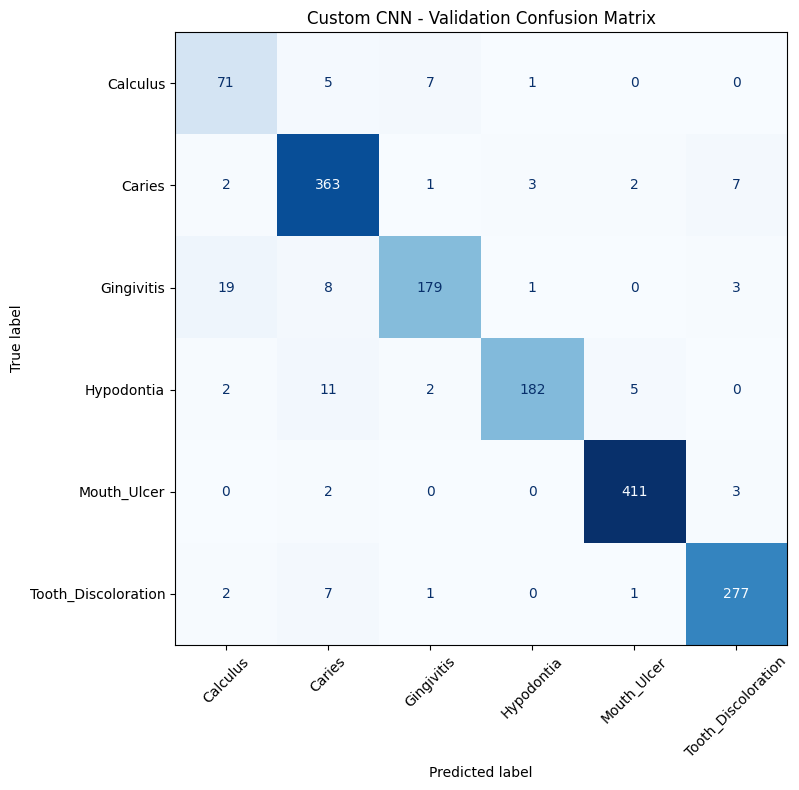


Confusion Matrix: MobileNetV2
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 162ms/step


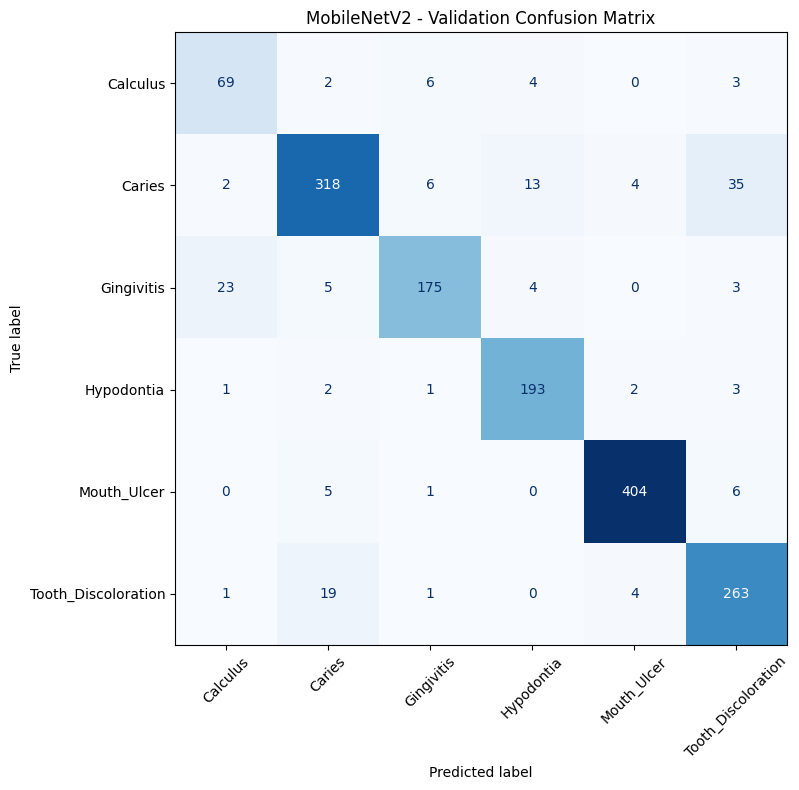


Confusion Matrix: EfficientNetB0
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 259ms/step


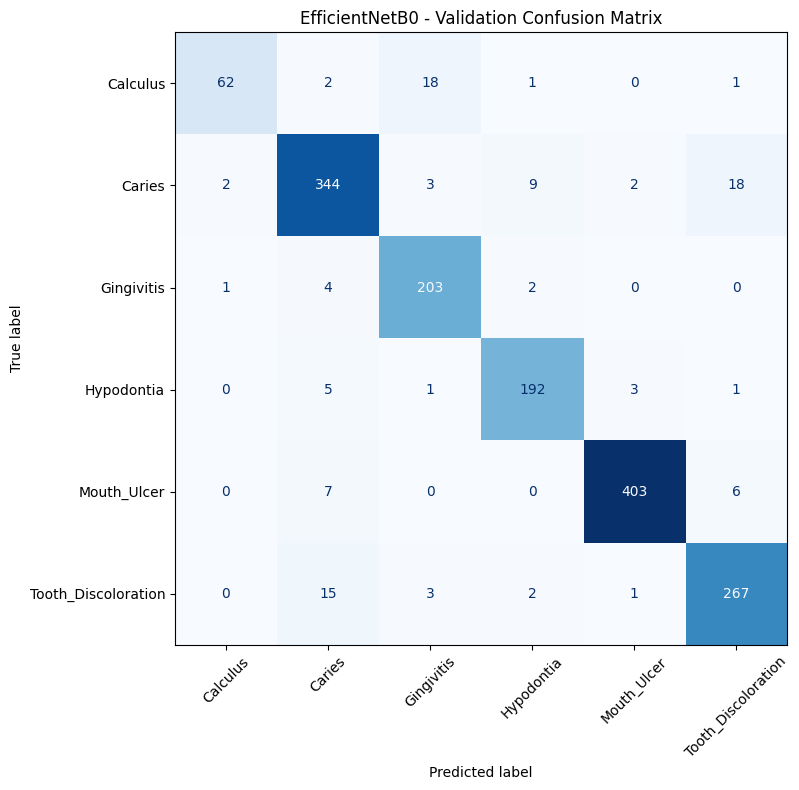

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

models_to_compare = {
    "Custom CNN": custom_cnn_best,
    "MobileNetV2": mobilenet_best,
    "EfficientNetB0": efficientnet_best
}

# Actual labels
y_true = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

for model_name, model in models_to_compare.items():
    print(f"\nConfusion Matrix: {model_name}")

    y_prob = model.predict(val_ds, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES)))
    )

    fig, ax = plt.subplots(figsize=(10, 8))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} - Validation Confusion Matrix")
    plt.tight_layout()
    plt.show()



Evaluating Custom CNN on Test Dataset...
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step

Evaluating MobileNetV2 on Test Dataset...
48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 149ms/step

Evaluating EfficientNetB0 on Test Dataset...
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 219ms/step


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Custom CNN,0.9244,0.8892,0.8829,0.8843
1,MobileNetV2,0.8988,0.8790,0.8721,0.8742
2,EfficientNetB0,0.9231,0.9122,0.8735,0.8868



Classification Report: Custom CNN
                     precision    recall  f1-score   support

           Calculus     0.6761    0.7619    0.7164        63
             Caries     0.9240    0.9642    0.9437       391
         Gingivitis     0.8639    0.8209    0.8418       201
         Hypodontia     0.9630    0.8125    0.8814       160
        Mouth_Ulcer     0.9725    0.9815    0.9770       432
Tooth_Discoloration     0.9357    0.9562    0.9458       274

           accuracy                         0.9244      1521
          macro avg     0.8892    0.8829    0.8843      1521
       weighted avg     0.9258    0.9244    0.9241      1521


Classification Report: MobileNetV2
                     precision    recall  f1-score   support

           Calculus     0.7931    0.7302    0.7603        63
             Caries     0.9252    0.8542    0.8883       391
         Gingivitis     0.8964    0.8607    0.8782       201
         Hypodontia     0.8875    0.8875    0.8875       160
        Mo

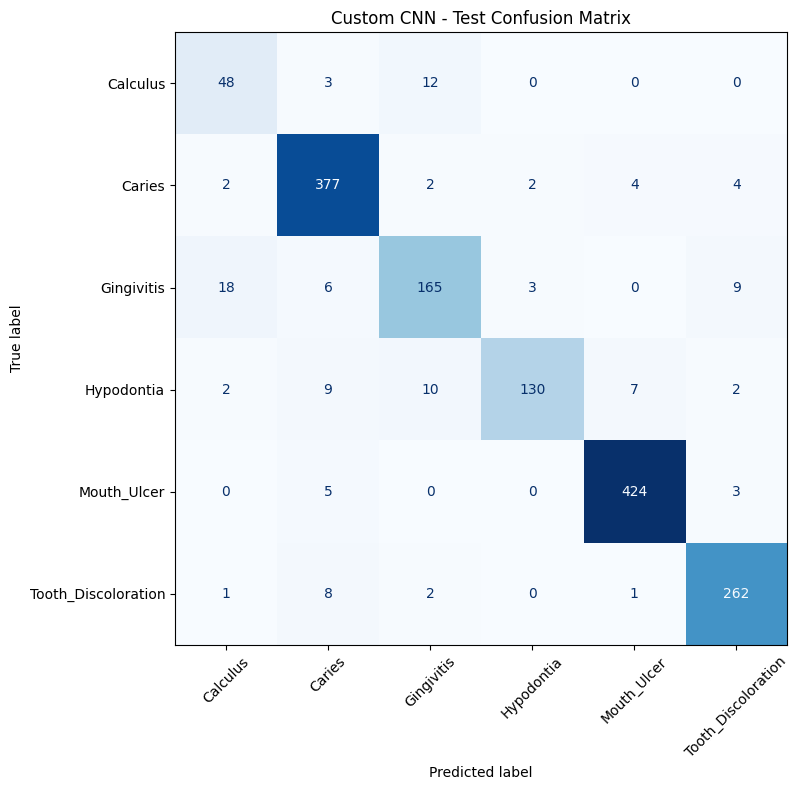

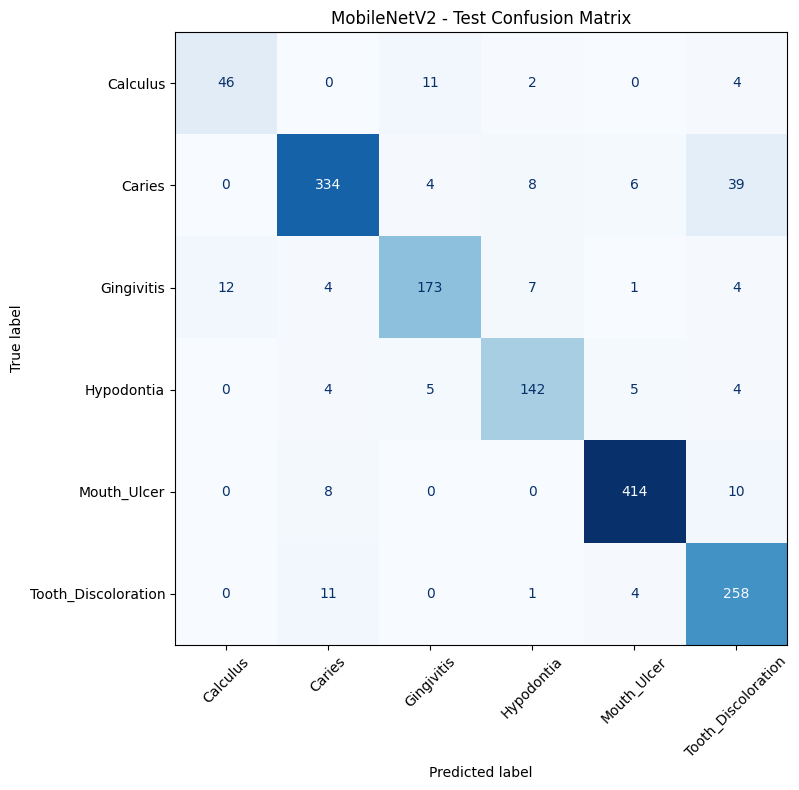

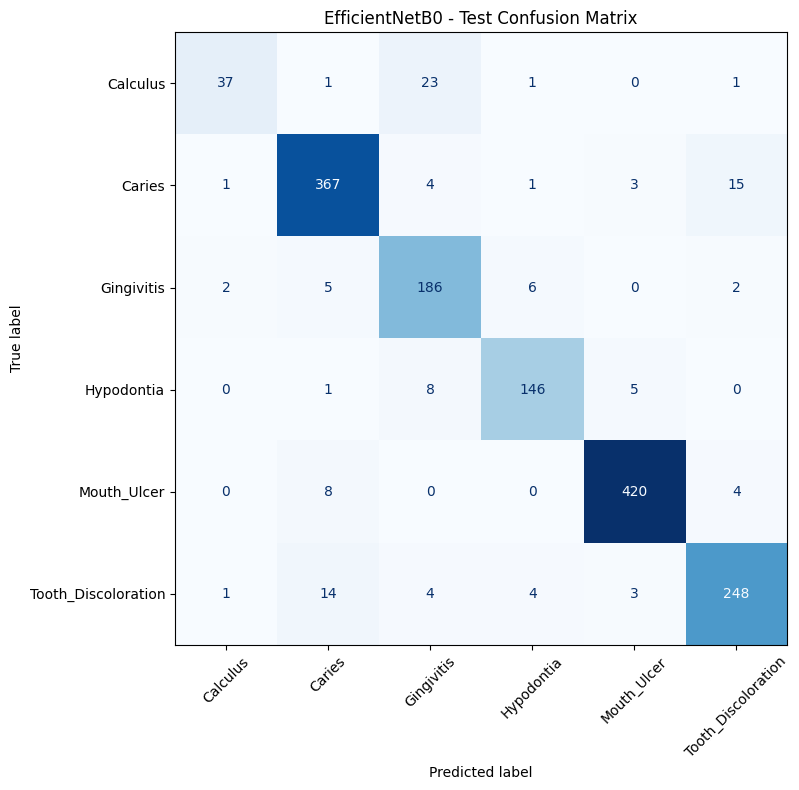

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# Models to evaluate
models_to_compare = {
    "Custom CNN": custom_cnn_best,
    "MobileNetV2": mobilenet_best,
    "EfficientNetB0": efficientnet_best
}

# Actual labels from the test dataset
y_test_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

results = []
test_predictions = {}

for model_name, model in models_to_compare.items():
    print(f"\nEvaluating {model_name} on Test Dataset...")

    y_prob = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)

    test_predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_true, y_pred),
        "Precision (Macro)": precision_score(
            y_test_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test_true, y_pred, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_test_true, y_pred, average="macro", zero_division=0
        )
    })

# Display comparison table
test_results_df = pd.DataFrame(results)

display(
    test_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision (Macro)": "{:.4f}",
        "Recall (Macro)": "{:.4f}",
        "F1-score (Macro)": "{:.4f}"
    })
)

# Display detailed classification reports
for model_name, y_pred in test_predictions.items():
    print(f"\n{'=' * 60}")
    print(f"Classification Report: {model_name}")
    print("=" * 60)

    print(classification_report(
        y_test_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        zero_division=0,
        digits=4
    ))

# Plot test confusion matrices
for model_name, y_pred in test_predictions.items():
    cm = confusion_matrix(
        y_test_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES)))
    )

    fig, ax = plt.subplots(figsize=(10, 8))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} - Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [ ]:
import os
import pandas as pd
from sklearn.metrics import classification_report

# Create evaluation results folder
RESULTS_PATH = os.path.join(BASE_PATH, "evaluation_results")
os.makedirs(RESULTS_PATH, exist_ok=True)

# Save overall model comparison
test_results_df.to_csv(
    os.path.join(RESULTS_PATH, "test_model_comparison.csv"),
    index=False
)

# Save detailed classification reports
for model_name, y_pred in test_predictions.items():

    report = classification_report(
        y_test_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        zero_division=0,
        output_dict=True
    )

    report_df = pd.DataFrame(report).transpose()

    safe_name = model_name.lower().replace(" ", "_")

    report_df.to_csv(
        os.path.join(
            RESULTS_PATH,
            f"{safe_name}_classification_report.csv"
        )
    )

print("Evaluation results saved successfully!")
print("Location:", RESULTS_PATH)

print("\nSaved files:")
for filename in os.listdir(RESULTS_PATH):
    print("-", filename)

Evaluation results saved successfully!
Location: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/evaluation_results

Saved files:
- test_model_comparison.csv
- custom_cnn_classification_report.csv
- mobilenetv2_classification_report.csv
- efficientnetb0_classification_report.csv


In [ ]:
import pandas as pd
import os

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

manifest_path = os.path.join(
    BASE_PATH,
    "dataset_split_manifest.csv"
)

df = pd.read_csv(manifest_path)

print("Total images:", len(df))
print("\nImages per split:")
print(df["Split"].value_counts())

print("\nClass distribution per split:")
print(pd.crosstab(df["Class"], df["Split"]))

# Check duplicate image paths across different splits
if "Path" in df.columns:
    path_split_counts = df.groupby("Path")["Split"].nunique()
    overlapping_paths = path_split_counts[path_split_counts > 1]

    print("\nPaths appearing in multiple splits:", len(overlapping_paths))
else:
    print("\nPath column not found.")

Total images: 10264

Images per split:
Split
train         7165
validation    1578
test          1521
Name: count, dtype: int64

Class distribution per split:
Split                test  train  validation
Class                                       
Calculus               63    302          84
Caries                391   1804         378
Gingivitis            201    825         210
Hypodontia            160    853         202
Mouth_Ulcer           432   1936         416
Tooth_Discoloration   274   1445         288

Paths appearing in multiple splits: 0


In [ ]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

split_path = os.path.join(BASE_PATH, "dataset_split_manifest.csv")
hash_path = os.path.join(BASE_PATH, "image_hash_manifest.csv")

split_df = pd.read_csv(split_path)
hash_df = pd.read_csv(hash_path)

print("Split manifest columns:")
print(split_df.columns.tolist())

print("\nHash manifest columns:")
print(hash_df.columns.tolist())

print("\nPreview of hash manifest:")
display(hash_df.head())

print("\nPreview of split manifest:")
display(split_df.head())

Split manifest columns:
['SHA256', 'Class', 'Source_Folder', 'Filename', 'Path', 'Copies_Found', 'pHash', 'Similarity_Group', 'Split']

Hash manifest columns:
['SHA256', 'Class', 'Source_Folder', 'Filename', 'Path', 'Copies_Found', 'pHash']

Preview of hash manifest:


,SHA256,Class,Source_Folder,Filename,Path,Copies_Found,pHash
0,18101a5c00af51ffb6a8aea6f4141f9a58c0df491f3ffa...,Calculus,Calculus,(1265).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,1,9214f72a60dd973a
1,6ab8af47c9e9000432a917230fe895be3e9c7f41cd4204...,Calculus,Calculus,(1266).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,1,eae535d452e0dec0
2,c9748614d9387f915d1a5aeb50dc9454dbef1ce9a2d806...,Calculus,Calculus,(1253).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,3,bf1fa14a5aa52d30
3,9b9e772306224691b0441b58ee04fcea18aa125ff89854...,Calculus,Calculus,(1213).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,2,f3783ce6ff818028
4,0da90068d4e6efc29e8e38646e6da81cd8dc6ec9f6f0ea...,Calculus,Calculus,(128).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,1,875baa6b3aa499a4



Preview of split manifest:


,SHA256,Class,Source_Folder,Filename,Path,Copies_Found,pHash,Similarity_Group,Split
0,6ab8af47c9e9000432a917230fe895be3e9c7f41cd4204...,Calculus,Calculus,(1266).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,1,eae535d452e0dec0,2,train
1,c9748614d9387f915d1a5aeb50dc9454dbef1ce9a2d806...,Calculus,Calculus,(1253).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,3,bf1fa14a5aa52d30,3,train
2,0da90068d4e6efc29e8e38646e6da81cd8dc6ec9f6f0ea...,Calculus,Calculus,(128).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,1,875baa6b3aa499a4,5,train
3,02b0fea7264363afeddc231a9434ae5d4623d70b59c593...,Calculus,Calculus,(1280).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,1,875baa6b3aa499a4,5,train
4,3cdda3846e9c6c45f338c60a16b0814a3ac68fa39173d6...,Calculus,Calculus,(1204).jpg,/content/drive/MyDrive/Sprint2_Oral_Disease_Cl...,2,ca7961f89760b0e5,6,train


In [ ]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

manifest_path = os.path.join(
    BASE_PATH,
    "dataset_split_manifest.csv"
)

df = pd.read_csv(manifest_path)

# 1. Check exact duplicate images across splits
exact_duplicates = (
    df.groupby("SHA256")
      .agg(
          Copies=("Path", "count"),
          Splits=("Split", "nunique"),
          Split_Names=("Split", lambda x: ", ".join(sorted(set(x)))),
          Classes=("Class", lambda x: ", ".join(sorted(set(x))))
      )
      .reset_index()
)

exact_leakage = exact_duplicates[
    (exact_duplicates["Copies"] > 1) &
    (exact_duplicates["Splits"] > 1)
]

# 2. Check similarity groups across splits
similarity_leakage = pd.DataFrame()

if "Similarity_Group" in df.columns:
    grouped = df[df["Similarity_Group"].notna()].groupby(
        "Similarity_Group"
    ).agg(
        Images=("Path", "count"),
        Splits=("Split", "nunique"),
        Split_Names=("Split", lambda x: ", ".join(sorted(set(x)))),
        Classes=("Class", lambda x: ", ".join(sorted(set(x))))
    ).reset_index()

    similarity_leakage = grouped[
        (grouped["Images"] > 1) &
        (grouped["Splits"] > 1)
    ]

print("========== EXACT DUPLICATE CHECK ==========")
print("Exact duplicate hashes across different splits:", len(exact_leakage))

if len(exact_leakage) > 0:
    display(exact_leakage.head(20))
else:
    print("No exact duplicate leakage detected.")

print("\n========== SIMILARITY GROUP CHECK ==========")
print("Similarity groups appearing across different splits:",
      len(similarity_leakage))

if len(similarity_leakage) > 0:
    display(similarity_leakage.head(30))
else:
    print("No cross-split similarity groups detected.")

========== EXACT DUPLICATE CHECK ==========
Exact duplicate hashes across different splits: 0
No exact duplicate leakage detected.

========== SIMILARITY GROUP CHECK ==========
Similarity groups appearing across different splits: 0
No cross-split similarity groups detected.


In [ ]:
!pip install -q gradio

In [ ]:
import os
import tensorflow as tf
import numpy as np
from PIL import Image

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
MODEL_PATH = os.path.join(
    BASE_PATH,
    "models",
    "efficientnetb0_fixed_best.keras"
)

# Load the selected model
model = tf.keras.models.load_model(MODEL_PATH)

# Class names in the same order used during training
CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth_Ulcer",
    "Tooth_Discoloration"
]

IMG_SIZE = (224, 224)

print("Model loaded successfully!")
print("Number of classes:", len(CLASS_NAMES))
print("Model output shape:", model.output_shape)

Model loaded successfully!
Number of classes: 6
Model output shape: (None, 6)


In [ ]:
def predict_oral_disease(image):
    if image is None:
        return {}

    # Convert image to RGB
    image = image.convert("RGB")

    # Resize image
    image = image.resize(IMG_SIZE)

    # Convert to NumPy array and normalize
    image_array = np.array(image, dtype=np.float32) / 255.0

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict
    predictions = model.predict(image_array, verbose=0)[0]

    # Return class probabilities
    results = {
        CLASS_NAMES[i]: float(predictions[i])
        for i in range(len(CLASS_NAMES))
    }

    return dict(sorted(
        results.items(),
        key=lambda item: item[1],
        reverse=True
    ))

print("Prediction function created successfully!")

Prediction function created successfully!


In [ ]:
import gradio as gr

demo = gr.Interface(
    fn=predict_oral_disease,
    inputs=gr.Image(
        type="pil",
        label="Upload an Oral Image"
    ),
    outputs=gr.Label(
        num_top_classes=6,
        label="Prediction Results"
    ),
    title="Oral Disease Classification",
    description=(
        "Upload an oral image to see the model's predictions "
        "for six categories: Calculus, Caries, Gingivitis, "
        "Hypodontia, Mouth Ulcer, and Tooth Discoloration."
    ),
    flagging_mode="never"
)

print("Gradio interface created successfully!")

Gradio interface created successfully!


In [ ]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://05272e99e58c8aaeb0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import numpy as np
from PIL import Image

# Medical UI theme
medical_theme = gr.themes.Soft(
    primary_hue="teal",
    secondary_hue="blue",
    neutral_hue="slate",
    font=[gr.themes.GoogleFont("Inter"), "Arial", "sans-serif"]
)

custom_css = """
.gradio-container {
    max-width: 1150px !important;
    margin: auto !important;
    background: #f4f8fb !important;
}

#hero {
    background: linear-gradient(135deg, #103b5c, #087e8b);
    padding: 32px;
    border-radius: 20px;
    color: white;
    text-align: center;
    margin-bottom: 22px;
}

#hero h1 {
    font-size: 34px;
    margin-bottom: 10px;
    color: white;
}

#hero p {
    font-size: 16px;
    color: #e0f7fa;
}

.section-card {
    background: white;
    border: 1px solid #dce8ef;
    border-radius: 16px;
    padding: 18px;
}

#analyze-btn {
    background: #087e8b;
    color: white;
    border-radius: 10px;
    font-weight: 700;
    border: none;
}

#analyze-btn:hover {
    background: #066873;
}

#medical-note {
    background: #fff8e7;
    border-left: 5px solid #e8ad35;
    padding: 15px;
    border-radius: 10px;
    color: #634b16;
    margin-top: 20px;
}

.footer {
    text-align: center;
    color: #64748b;
    font-size: 13px;
    padding: 20px;
}
"""

def predict_oral_disease(image):
    if image is None:
        return None, {}, "Please upload an image first."

    image = image.convert("RGB").resize(IMG_SIZE)

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    predictions = model.predict(image_array, verbose=0)[0]

    results = {
        CLASS_NAMES[i]: float(predictions[i])
        for i in range(len(CLASS_NAMES))
    }

    predicted_class = CLASS_NAMES[int(np.argmax(predictions))]
    confidence = float(np.max(predictions)) * 100

    summary = (
        f"### Predicted Category: {predicted_class}\n"
        f"**Model score:** {confidence:.2f}%\n\n"
        "This score reflects the model's output, not a confirmed "
        "medical diagnosis."
    )

    return image, results, summary


with gr.Blocks(
    theme=medical_theme,
    css=custom_css,
    title="OralCare AI | Oral Image Classification"
) as demo:

    gr.HTML("""
    <div id="hero">
        <h1>🦷 OralCare AI</h1>
        <p>AI-Powered Oral Disease Image Classification</p>
        <p>
            An academic AI project exploring image classification
            across six oral condition categories.
        </p>
    </div>
    """)

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("## 📤 Upload Oral Image")

            input_image = gr.Image(
                type="pil",
                label="Oral Image",
                height=330
            )

            gr.Markdown(
                "Upload a clear image relevant to one of the "
                "six categories supported by the model."
            )

            analyze_btn = gr.Button(
                "Analyze Image",
                elem_id="analyze-btn",
                variant="primary"
            )

            clear_btn = gr.ClearButton(
                components=[],
                value="Clear"
            )

        with gr.Column(scale=1):
            gr.Markdown("## 🔬 Analysis Results")

            output_image = gr.Image(
                label="Image Submitted for Analysis",
                height=250,
                interactive=False
            )

            output_summary = gr.Markdown(
                "Upload an image and select **Analyze Image** "
                "to view the model output."
            )

    with gr.Row():
        with gr.Column(elem_classes=["section-card"]):
            gr.Markdown("### 📊 Class Scores")

            output_scores = gr.Label(
                num_top_classes=6,
                label="Model Output"
            )

    analyze_btn.click(
        fn=predict_oral_disease,
        inputs=input_image,
        outputs=[output_image, output_scores, output_summary]
    )

    clear_btn.add(
        [input_image, output_image, output_scores, output_summary]
    )

    gr.HTML("""
    <div id="medical-note">
        <strong>Medical Disclaimer</strong><br>
        This application is an academic research prototype.
        Its predictions are not a medical diagnosis and must not
        be used to make treatment decisions. Consult a qualified
        dental professional for clinical assessment.
    </div>

    <div class="footer">
        OralCare AI · Academic Machine Learning Project
    </div>
    """)

print("Medical interface created successfully!")

Application code saved successfully!
File: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/app.py
Model exists: True


In [ ]:
import gradio as gr
import numpy as np
from PIL import Image

# Medical UI theme
medical_theme = gr.themes.Soft(
    primary_hue="teal",
    secondary_hue="blue",
    neutral_hue="slate",
    font=[gr.themes.GoogleFont("Inter"), "Arial", "sans-serif"]
)

custom_css = """
.gradio-container {
    max-width: 1150px !important;
    margin: auto !important;
    background: #f4f8fb !important;
}

#hero {
    background: linear-gradient(135deg, #103b5c, #087e8b);
    padding: 32px;
    border-radius: 20px;
    color: white;
    text-align: center;
    margin-bottom: 22px;
}

#hero h1 {
    font-size: 34px;
    margin-bottom: 10px;
    color: white;
}

#hero p {
    font-size: 16px;
    color: #e0f7fa;
}

.section-card {
    background: white;
    border: 1px solid #dce8ef;
    border-radius: 16px;
    padding: 18px;
}
/* Black text for Class Scores heading */
.section-card h3 {
    color: #000000 !important;
}

/* Black text for Important Medical Notice heading */
#medical-note strong {
    color: #000000 !important;
}
#analyze-btn {
    background: #087e8b;
    color: white;
    border-radius: 10px;
    font-weight: 700;
    border: none;
}

#analyze-btn:hover {
    background: #066873;
}

#medical-note {
    background: #fff8e7;
    border-left: 5px solid #e8ad35;
    padding: 15px;
    border-radius: 10px;
    color: #634b16;
    margin-top: 20px;
}

.footer {
    text-align: center;
    color: #64748b;
    font-size: 13px;
    padding: 20px;
}
"""

def predict_oral_disease(image):
    if image is None:
        return None, {}, "Please upload an image first."

    image = image.convert("RGB").resize(IMG_SIZE)

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    predictions = model.predict(image_array, verbose=0)[0]

    results = {
        CLASS_NAMES[i]: float(predictions[i])
        for i in range(len(CLASS_NAMES))
    }

    predicted_class = CLASS_NAMES[int(np.argmax(predictions))]
    confidence = float(np.max(predictions)) * 100

    summary = (
        f"### Predicted Category: {predicted_class}\n"
        f"**Model score:** {confidence:.2f}%\n\n"
        "This score reflects the model's output, not a confirmed "
        "medical diagnosis."
    )

    return image, results, summary


with gr.Blocks(
    theme=medical_theme,
    css=custom_css,
    title="OralCare AI | Oral Image Classification"
) as demo:

    gr.HTML("""
    <div id="hero">
        <h1>🦷 OralCare AI</h1>
        <p>AI-Powered Oral Disease Image Classification</p>
        <p>
            AI project exploring image classification
            across six oral condition categories.
        </p>
    </div>
    """)

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("## 📤 Upload Oral Image")

            input_image = gr.Image(
                type="pil",
                label="Oral Image",
                height=330
            )

            gr.Markdown(
                "Upload a clear image relevant to one of the "
                "six categories supported by the model."
            )

            analyze_btn = gr.Button(
                "Analyze Image",
                elem_id="analyze-btn",
                variant="primary"
            )

            clear_btn = gr.ClearButton(
                components=[],
                value="Clear"
            )

        with gr.Column(scale=1):
            gr.Markdown("## 🔬 Analysis Results")

            output_image = gr.Image(
                label="Image Submitted for Analysis",
                height=250,
                interactive=False
            )

            output_summary = gr.Markdown(
                "Upload an image and select **Analyze Image** "
                "to view the model output."
            )

    with gr.Row():
        with gr.Column(elem_classes=["section-card"]):
            gr.Markdown("### 📊 Class Scores")

            output_scores = gr.Label(
                num_top_classes=6,
                label="Model Output"
            )

    analyze_btn.click(
        fn=predict_oral_disease,
        inputs=input_image,
        outputs=[output_image, output_scores, output_summary]
    )

    clear_btn.add(
        [input_image, output_image, output_scores, output_summary]
    )

    gr.HTML("""

      <div id="medical-note">
          <strong>⚕️ Important Medical Notice</strong><br>
          OralCare AI uses artificial intelligence to classify oral
          images into six categories. Its predictions are intended
          for informational purposes only and are not a substitute
          for professional dental diagnosis or medical advice.
          Please consult a qualified dental professional for
          accurate assessment and treatment recommendations.
      </div>



    <div class="footer">
        OralCare AI · Developed by Hassan Saleh
    </div>
    """)

print("Medical interface created successfully!")

/tmp/ipykernel_1482/3012687093.py:113: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Medical interface created successfully!


In [ ]:
demo.launch(
    share=True,
    theme=medical_theme,
    css=custom_css
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bc6838b337240c7a36.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

required_paths = [
    os.path.join(BASE_PATH, "app.py"),
    os.path.join(BASE_PATH, "models", "efficientnetb0_fixed_best.keras"),
    os.path.join(BASE_PATH, "evaluation_results", "test_model_comparison.csv"),
]

for path in required_paths:
    print(
        f"{'FOUND' if os.path.exists(path) else 'MISSING'}: "
        f"{os.path.relpath(path, BASE_PATH)}"
    )

MISSING: app.py
FOUND: models/efficientnetb0_fixed_best.keras
FOUND: evaluation_results/test_model_comparison.csv


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"
MODELS_PATH = os.path.join(BASE_PATH, "models")

os.makedirs(BASE_PATH, exist_ok=True)

APP_CODE = r'''
import os
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image

BASE_PATH = os.path.dirname(os.path.abspath(__file__))

MODEL_PATH = os.path.join(
    BASE_PATH,
    "models",
    "efficientnetb0_fixed_best.keras"
)

CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth_Ulcer",
    "Tooth_Discoloration"
]

IMG_SIZE = (224, 224)

model = tf.keras.models.load_model(MODEL_PATH)


def predict_oral_disease(image):
    if image is None:
        return None, {}, "Please upload an image first."

    image = image.convert("RGB").resize(IMG_SIZE)

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    predictions = model.predict(image_array, verbose=0)[0]

    results = {
        CLASS_NAMES[i]: float(predictions[i])
        for i in range(len(CLASS_NAMES))
    }

    predicted_class = CLASS_NAMES[int(np.argmax(predictions))]
    score = float(np.max(predictions)) * 100

    summary = (
        f"### Predicted Category: {predicted_class}\n\n"
        f"**Model Score:** {score:.2f}%\n\n"
        "This score represents the model output and does not "
        "confirm the presence of a medical condition."
    )

    return image, results, summary


medical_theme = gr.themes.Soft(
    primary_hue="teal",
    secondary_hue="blue",
    neutral_hue="slate"
)

custom_css = """
.gradio-container {
    max-width: 1150px !important;
    margin: auto !important;
    background: #f4f8fb !important;
}

#hero {
    background: linear-gradient(135deg, #103b5c, #087e8b);
    padding: 32px;
    border-radius: 20px;
    color: white;
    text-align: center;
    margin-bottom: 22px;
}

#hero h1 {
    font-size: 34px;
    color: white !important;
}

#hero p {
    color: #e0f7fa !important;
    font-size: 16px;
}

.section-card {
    background: white;
    border: 1px solid #dce8ef;
    border-radius: 16px;
    padding: 18px;
}

#analyze-btn {
    background: #087e8b;
    color: white;
    border-radius: 10px;
    font-weight: 700;
}

#medical-note {
    background: #fff8e7;
    border-left: 5px solid #e8ad35;
    padding: 15px;
    border-radius: 10px;
    color: #000000 !important;
    margin-top: 20px;
}

#medical-note strong,
.gradio-container h3 {
    color: #000000 !important;
}

.footer {
    text-align: center;
    color: #64748b;
    font-size: 13px;
    padding: 20px;
}
"""


with gr.Blocks(
    title="OralCare AI | Oral Image Classification"
) as demo:

    gr.HTML("""
    <div id="hero">
        <h1>🦷 OralCare AI</h1>
        <p>AI-Powered Oral Disease Image Classification</p>
        <p>
            Intelligent image classification across six oral
            condition categories.
        </p>
    </div>
    """)

    with gr.Row():
        with gr.Column():
            gr.Markdown("## 📤 Upload Oral Image")

            input_image = gr.Image(
                type="pil",
                label="Oral Image",
                height=330
            )

            gr.Markdown(
                "Upload a clear image relevant to one of the "
                "six categories supported by the model."
            )

            analyze_btn = gr.Button(
                "Analyze Image",
                elem_id="analyze-btn",
                variant="primary"
            )

            clear_btn = gr.ClearButton(value="Clear")

        with gr.Column():
            gr.Markdown("## 🔬 Analysis Results")

            output_image = gr.Image(
                label="Submitted Image",
                height=250,
                interactive=False
            )

            output_summary = gr.Markdown(
                "Upload an image and select **Analyze Image** "
                "to view the model output."
            )

    with gr.Row():
        with gr.Column(elem_classes=["section-card"]):
            gr.Markdown("### 📊 Class Scores")

            output_scores = gr.Label(
                num_top_classes=6,
                label="Model Output"
            )

    analyze_btn.click(
        fn=predict_oral_disease,
        inputs=input_image,
        outputs=[output_image, output_scores, output_summary]
    )

    clear_btn.add(
        [input_image, output_image, output_scores, output_summary]
    )

    gr.HTML("""
    <div id="medical-note">
        <strong>⚕️ Important Medical Notice</strong><br>
        OralCare AI uses artificial intelligence to classify
        oral images into six categories. Its predictions are
        intended for informational purposes only and are not
        a substitute for professional dental diagnosis or
        medical advice. Consult a qualified dental professional
        for accurate assessment and treatment recommendations.
    </div>

    <div class="footer">
        OralCare AI · Developed by Hassan Saleh
    </div>
    """)


if __name__ == "__main__":
    demo.launch()
'''

app_path = os.path.join(BASE_PATH, "app.py")

with open(app_path, "w", encoding="utf-8") as file:
    file.write(APP_CODE)

print("App file created:", os.path.exists(app_path))
print("App path:", app_path)
print(
    "Model available:",
    os.path.exists(
        os.path.join(MODELS_PATH, "efficientnetb0_fixed_best.keras")
    )
)

App file created: True
App path: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/app.py
Model available: True


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

requirements = """tensorflow
gradio
numpy
Pillow
"""

requirements_path = os.path.join(BASE_PATH, "requirements.txt")

with open(requirements_path, "w", encoding="utf-8") as file:
    file.write(requirements)

print("Requirements file created:", os.path.exists(requirements_path))
print("\nFile content:\n")
with open(requirements_path, "r", encoding="utf-8") as file:
    print(file.read())

Requirements file created: True

File content:

tensorflow
gradio
numpy
Pillow



In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

README_CONTENT = """# OralCare AI
## AI-Powered Oral Disease Image Classification

**Developed by Hassan Saleh**

OralCare AI is an AI-powered image classification application designed
to classify oral images into six categories using deep learning.

## Features
- Upload oral images for classification.
- Display the predicted category.
- View model scores for all six categories.
- Medical-inspired user interface.

## Supported Categories
1. Calculus
2. Caries
3. Gingivitis
4. Hypodontia
5. Mouth Ulcer
6. Tooth Discoloration

## Models Evaluated
- Custom CNN
- MobileNetV2
- EfficientNetB0

## Test Results

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| Custom CNN | 92.44% | 88.43% |
| MobileNetV2 | 89.88% | 87.42% |
| EfficientNetB0 | 92.31% | 88.68% |

The test set contains 1,521 images. EfficientNetB0 is the current
deployment candidate based on its macro F1-score.

## Technology Stack
- Python
- TensorFlow / Keras
- Gradio
- NumPy
- Pillow

## Project Structure

    Sprint2_Oral_Disease_Classification/
    ├── app.py
    ├── requirements.txt
    ├── README.md
    ├── models/
    │   └── efficientnetb0_fixed_best.keras
    └── evaluation_results/

## Run Locally

Install dependencies:

    pip install -r requirements.txt

Start the application:

    python app.py

Make sure the trained model exists at:

    models/efficientnetb0_fixed_best.keras

## Medical Disclaimer

OralCare AI is intended for informational purposes and portfolio
demonstration. Its predictions are not a medical diagnosis and are
not a substitute for professional dental examination, diagnosis,
or treatment. Consult a qualified dental professional for medical advice.

## Author

Hassan Saleh
"""

readme_path = os.path.join(BASE_PATH, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(README_CONTENT)

print("README created:", os.path.exists(readme_path))
print("Location:", readme_path)
print("Size:", os.path.getsize(readme_path), "bytes")

README created: True
Location: /content/drive/MyDrive/Sprint2_Oral_Disease_Classification/README.md
Size: 1710 bytes


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/Sprint2_Oral_Disease_Classification"

required_files = {
    "Application": os.path.join(BASE_PATH, "app.py"),
    "Requirements": os.path.join(BASE_PATH, "requirements.txt"),
    "README": os.path.join(BASE_PATH, "README.md"),
    "Model": os.path.join(
        BASE_PATH, "models", "efficientnetb0_fixed_best.keras"
    ),
    "Evaluation Results": os.path.join(
        BASE_PATH, "evaluation_results", "test_model_comparison.csv"
    ),
}

print("========== DEPLOYMENT FILE CHECK ==========")

all_found = True

for name, path in required_files.items():
    exists = os.path.exists(path)
    print(f"{'PASS' if exists else 'MISSING'} | {name}")

    if not exists:
        all_found = False

if all_found:
    print("\nAll required files are present.")
else:
    print("\nSome files are missing. Check the output above.")

========== DEPLOYMENT FILE CHECK ==========
PASS | Application
PASS | Requirements
PASS | README
PASS | Model
PASS | Evaluation Results

All required files are present.
